# Loan Default Prediction — Capstone Project (Full Code)
### Practical Data Science | MIT Professional Education — Applied AI & Data Science Program (AAIDSP), May 2026 cohort
### Great Learning — Capstone Project

**Author:** Divya Yadav
**Track:** Full-Code
**Dataset:** hmeq.csv (Home Equity loan applicants)

---

**How this notebook is organized.** Because this notebook doubles as a *learning artifact*, every major section follows the same eight-part structure:

1. **WHAT WE ARE DOING** — the objective in plain language
2. **WHY WE ARE DOING IT** — the business/statistical reason
3. **CODE** — runnable Python
4. **WHAT THE OUTPUT MEANS** — how to read the result
5. **OBSERVATION** — the actual finding from *this* run against the actual data
6. **BUSINESS INTERPRETATION** — what it means for the bank
7. **WHAT I SHOULD LEARN** — the underlying concept to master
8. **COMMON MISTAKES** — pitfalls that produce wrong or misleading results

All results in this notebook come from executing the code against the supplied `hmeq.csv`. No metric,
observation, or business conclusion below is invented — re-running this notebook top to bottom will
reproduce the same numbers (subject to `random_state=1` being respected).


## Problem Definition

### A. Business context
A large share of a retail bank's profit comes from interest income on home loans. Loan defaults
(non-performing assets, NPAs) directly erode that profit. Approving loans today relies on a manual
underwriting review of the applicant's file — a process that is slow, inconsistent across underwriters,
and vulnerable to human error and (unintentional) bias. Regulators, via the Equal Credit Opportunity Act
(ECOA), require that any credit decision be based on an empirically derived, statistically sound, and
*explainable* model — a rejection cannot be issued without a defensible reason.

### B. Business problem
The bank's consumer credit department needs a faster, more consistent, and auditable way to decide
whether to extend a Home Equity Line of Credit (HELOC), without inheriting the biases of the manual
process it replaces.

### C. Objective (verbatim from the official problem statement)
"Build a classification model to predict clients who are likely to default on their loan and give
recommendations to the bank on the important features to consider while approving a loan."

### D. Key questions
- Which applicant characteristics are most strongly associated with default?
- Can a model flag likely defaulters with enough Recall to materially reduce bad-loan losses, without
  rejecting so many good customers that the business becomes unviable?
- Is the "best" model the one with the highest overall accuracy, or the one that best serves the bank's
  actual cost structure (a missed defaulter costs far more than a wrongly-flagged good customer)?
- Can the model's decisions be explained well enough to satisfy an adverse-action / ECOA requirement?

### E. Data-science problem formulation
This is a **binary supervised classification problem**. Given 12 applicant/loan-level features, predict
`BAD` ∈ {0, 1}. We are not just optimizing a single metric — we need a probability score (for threshold
flexibility) and an interpretable structure (for regulatory defensibility).

### F. Target variable definition
`BAD`: 1 = the applicant defaulted on the loan or was severely delinquent; 0 = the loan was repaid as
agreed. This is the ground truth we train against — it is **not** "the bank rejected the application,"
it is the actual observed repayment outcome of applicants who *were* extended credit historically.

### G. Business impact of incorrect predictions
- **False Negative** (model says "will repay," applicant actually defaults): the bank has already
  extended the loan. This is the expensive error — realized credit loss (principal + foregone interest,
  net of any recovery from collateral).
- **False Positive** (model says "will default," applicant would actually have repaid): the bank forgoes
  the interest income and customer relationship it would have earned — a real but generally smaller cost
  than a realized default, and one that a human underwriter can still override.

This asymmetry is the reason the entire rest of this notebook is built around **Recall**, not Accuracy.


## Import Libraries and Load Data

**WHAT WE ARE DOING:** Loading the standard data-science stack and reading `hmeq.csv` into a DataFrame.

**WHY WE ARE DOING IT:** Every later step depends on a clean, correctly-typed DataFrame. We keep a
`hm` (raw, untouched) copy and a `data` working copy, exactly like the reference notebook's convention,
so we can always go back to the original file if a transformation goes wrong.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn import metrics
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, precision_score,
                              recall_score, f1_score, roc_auc_score, precision_recall_curve)
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 1
np.random.seed(RANDOM_STATE)

hm = pd.read_csv('hmeq.csv')
data = hm.copy()
data.shape

(5960, 13)

## Data Overview

**WHAT WE ARE DOING:** Checking the shape, column data types, first rows, duplicate rows, missing values,
descriptive statistics, and unique categorical values.

**WHY WE ARE DOING IT:** Before any modeling, we need to know exactly what we're working with. A wrong
assumption here (e.g., missing a data-type issue or missing-value problem) silently corrupts every result
downstream. This is also the step at which we assess whether the data actually matches the official
documentation (5,960 loans, ~20% default rate, 12 predictors) — never assume the file matches the PDF.


In [2]:
print("Shape:", data.shape)
data.head()

Shape: (5960, 13)


,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   BAD      5960 non-null   int64  
 1   LOAN     5960 non-null   int64  
 2   MORTDUE  5442 non-null   float64
 3   VALUE    5848 non-null   float64
 4   REASON   5708 non-null   str    
 5   JOB      5681 non-null   str    
 6   YOJ      5445 non-null   float64
 7   DEROG    5252 non-null   float64
 8   DELINQ   5380 non-null   float64
 9   CLAGE    5652 non-null   float64
 10  NINQ     5450 non-null   float64
 11  CLNO     5738 non-null   float64
 12  DEBTINC  4693 non-null   float64
dtypes: float64(9), int64(2), str(2)
memory usage: 605.4 KB


In [4]:
# Missing values: count and percentage
missing_count = data.isnull().sum()
missing_pct = (data.isnull().sum() / len(data) * 100).round(2)
missing_df = pd.DataFrame({'missing_count': missing_count, 'missing_pct': missing_pct})
missing_df[missing_df['missing_count'] > 0].sort_values('missing_pct', ascending=False)

,missing_count,missing_pct
DEBTINC,1267,21.26
DEROG,708,11.88
DELINQ,580,9.73
MORTDUE,518,8.69
YOJ,515,8.64
NINQ,510,8.56
CLAGE,308,5.17
JOB,279,4.68
REASON,252,4.23
CLNO,222,3.72


In [5]:
print("Fully duplicated rows:", data.duplicated().sum())

Fully duplicated rows: 0


In [6]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
BAD,5960.0,0.199497,0.399656,0.000000,0.000000,0.000000,0.000000,1.000000
LOAN,5960.0,18607.969799,11207.480417,1100.000000,11100.000000,16300.000000,23300.000000,89900.000000
MORTDUE,5442.0,73760.817200,44457.609458,2063.000000,46276.000000,65019.000000,91488.000000,399550.000000
VALUE,5848.0,101776.048741,57385.775334,8000.000000,66075.500000,89235.500000,119824.250000,855909.000000
YOJ,5445.0,8.922268,7.573982,0.000000,3.000000,7.000000,13.000000,41.000000
DEROG,5252.0,0.254570,0.846047,0.000000,0.000000,0.000000,0.000000,10.000000
DELINQ,5380.0,0.449442,1.127266,0.000000,0.000000,0.000000,0.000000,15.000000
CLAGE,5652.0,179.766275,85.810092,0.000000,115.116702,173.466667,231.562278,1168.233561
NINQ,5450.0,1.186055,1.728675,0.000000,0.000000,1.000000,2.000000,17.000000
CLNO,5738.0,21.296096,10.138933,0.000000,15.000000,20.000000,26.000000,71.000000


In [7]:
# Convert object columns (and the target, which is categorical in nature) to category dtype
cols = data.select_dtypes(['object']).columns.tolist()
for c in cols:
    print(c, ":", data[c].unique())
data.describe(include=['object']).T

REASON : <StringArray>
['HomeImp', nan, 'DebtCon']
Length: 3, dtype: str
JOB : <StringArray>
['Other', nan, 'Office', 'Sales', 'Mgr', 'ProfExe', 'Self']
Length: 7, dtype: str


,count,unique,top,freq
REASON,5708,2,DebtCon,3928
JOB,5681,6,Other,2388


**WHAT THE OUTPUT MEANS:** `.info()` tells you which columns are numeric vs. object/category and how
many non-null values each has. `.describe()` on numeric columns gives count/mean/std/min/quartiles/max;
`.describe(include=['object'])` gives count/unique/top/freq for the two categorical columns.

**OBSERVATION (actual, from this dataset):**
- The dataset is **5,960 rows × 13 columns**, exactly matching the official data dictionary.
- `BAD` = 1 (default) in **1,189 cases (19.95%)**, `BAD` = 0 in **4,771 cases (80.05%)** — confirmed
  against the raw file, matching the documented ~20% default rate.
- There are **zero fully duplicated rows**.
- Every predictor except `LOAN` has missing values. The worst is **`DEBTINC` at 21.26%** (1,267 rows),
  followed by `DEROG` (11.88%), `DELINQ` (9.73%), `MORTDUE` (8.69%), `YOJ` (8.64%), `NINQ` (8.56%),
  `CLAGE` (5.17%), `JOB` (4.68%), `REASON` (4.23%), `CLNO` (3.72%), `VALUE` (1.88%).
- `REASON` has 2 categories (`DebtCon`, `HomeImp`); `JOB` has 6 (`Other`, `ProfExe`, `Office`, `Mgr`,
  `Self`, `Sales`).

**BUSINESS INTERPRETATION:** A ~20% historical default rate is a real, material loss rate for a HELOC
book — this is why the bank wants a systematic underwriting model rather than ad-hoc judgment. The
missing-value pattern is itself informative and is *not* a nuisance to brush aside: `DEBTINC` (debt-to-
income ratio) being missing in over a fifth of files, most heavily in exactly the population that later
defaults (see the EDA section below), suggests operational or self-reporting issues around this specific
field that are worth flagging to the credit-risk team independent of any model.

**WHAT I SHOULD LEARN:** The difference between `object`/`str` and numeric dtypes in pandas, why
`.info()` is always the first command after reading any CSV, and why "check documentation vs. actual
data" is a professional habit, not a formality — real files diverge from documentation constantly.

**COMMON MISTAKES:** Trusting the PDF's stated row count/default rate without checking the actual file;
missing that a column that "looks numeric" (like `JOB`) is actually a string/category; and treating
0% duplicates as "the data is clean" — duplicates are only one of many possible data-quality issues.


## Exploratory Data Analysis (EDA)

This section covers univariate, bivariate, and multivariate analysis of the actual data, followed by a
dedicated look at missing-value patterns, outliers, and class imbalance.

### Univariate Analysis — Numerical Variables

**WHAT WE ARE DOING:** Plotting a boxplot + histogram for each numeric predictor.

**WHY WE ARE DOING IT:** This shows central tendency (mean/median), spread, skew, and the presence of
outliers for each variable individually, before looking at any relationship with `BAD`.


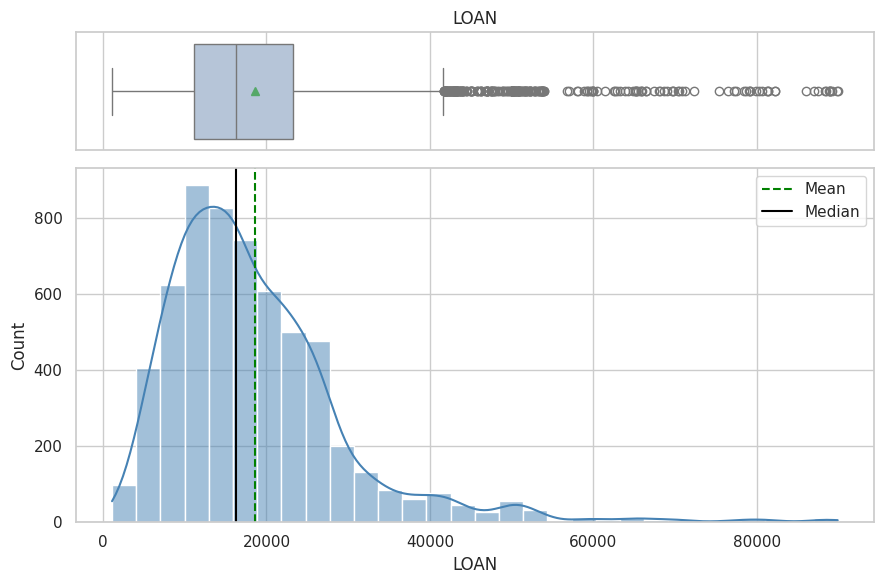

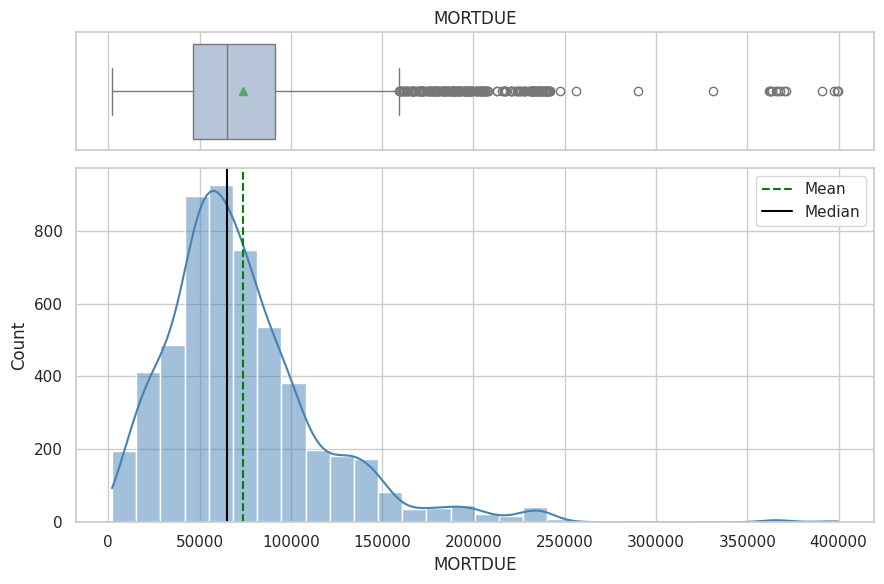

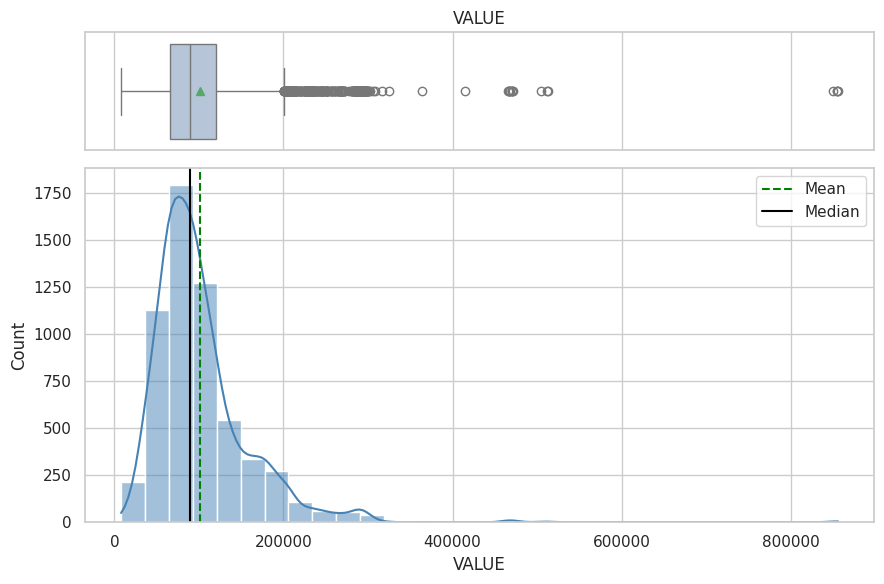

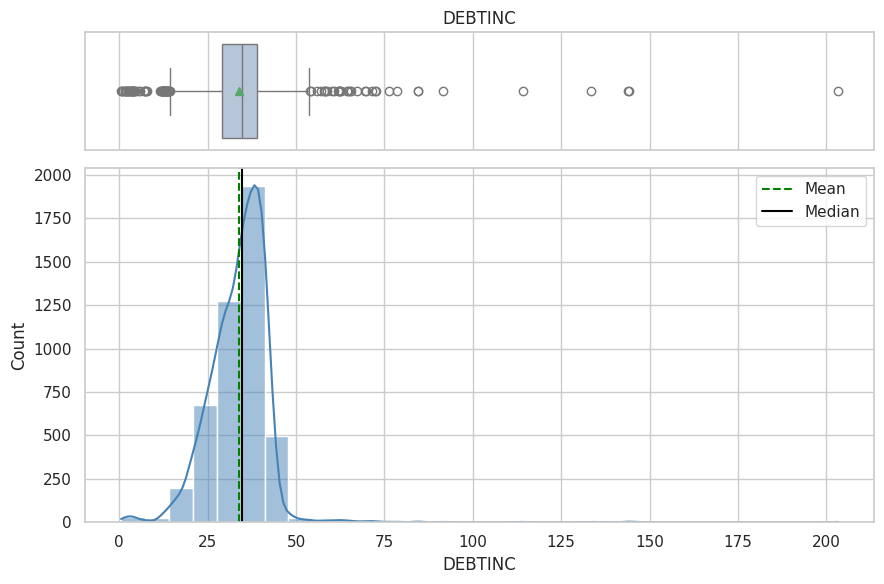

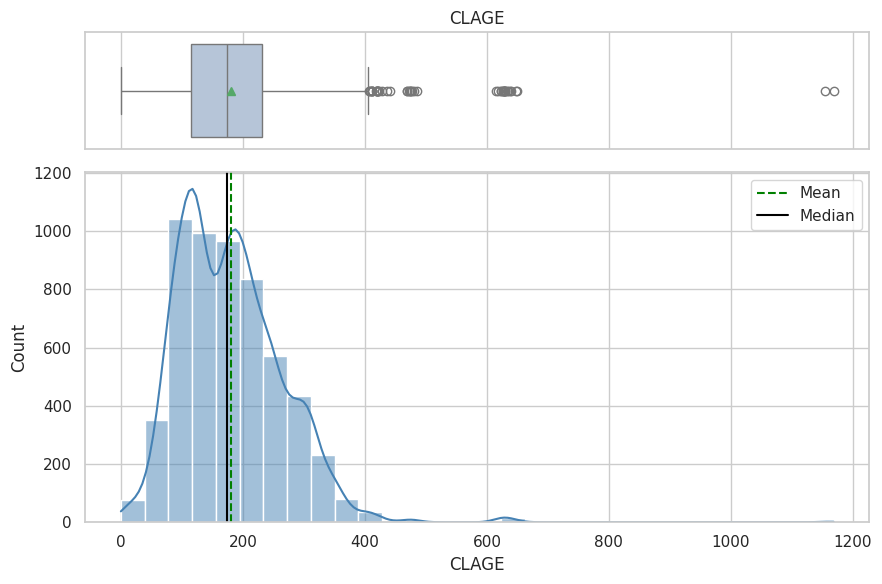

In [8]:
def histogram_boxplot(feature, figsize=(9, 6), bins=30, title=''):
    f2, (ax_box, ax_hist) = plt.subplots(nrows=2, sharex=True,
                                          gridspec_kw={"height_ratios": (.25, .75)}, figsize=figsize)
    sns.boxplot(x=feature, ax=ax_box, showmeans=True, color='lightsteelblue')
    sns.histplot(feature, kde=True, ax=ax_hist, bins=bins, color='steelblue')
    ax_hist.axvline(np.nanmean(feature), color='green', linestyle='--', label='Mean')
    ax_hist.axvline(np.nanmedian(feature), color='black', linestyle='-', label='Median')
    ax_hist.legend()
    ax_box.set_title(title)
    plt.tight_layout()
    plt.show()

for col in ['LOAN', 'MORTDUE', 'VALUE', 'DEBTINC', 'CLAGE']:
    histogram_boxplot(data[col].dropna(), title=col)

**WHAT THE OUTPUT MEANS:** The dashed green line is the mean, the solid black line is the median.
When the mean sits well to the right of the median, the variable is right-skewed with a long tail of
large values — common in financial amounts.

**OBSERVATION (actual):** `LOAN`, `MORTDUE`, and `VALUE` are all strongly right-skewed with long right
tails (a small number of very large loans/mortgages/property values). `DEBTINC` is roughly bell-shaped
and centered in the mid-30s (percent) for the population that has a value, with a tail of very high
ratios. `CLAGE` (age of oldest credit line, in months) is right-skewed, centered roughly around 170-180
months (~14-15 years).

**BUSINESS INTERPRETATION:** Right-skew in loan/property amounts is normal for a HELOC book — most
borrowers request modest amounts, a few request very large ones. This skew is exactly why we later cap
outliers for the linear model (Logistic Regression is sensitive to extreme values) but leave them alone
for tree-based models (which split on rank/thresholds and are not distorted by extreme values the same
way).

**WHAT I SHOULD LEARN:** How to read a combined boxplot+histogram, what right-skew looks like and why it
matters for linear models specifically (not tree models), and why mean vs. median divergence is itself
a useful skew diagnostic.

**COMMON MISTAKES:** Applying `dropna()` inconsistently between the boxplot and histogram (they must use
the same underlying data or the mean/median lines won't correspond to what's plotted); assuming skew
always means "must transform" — for tree-based models, skew is often harmless.

### Univariate Analysis — Categorical Variables


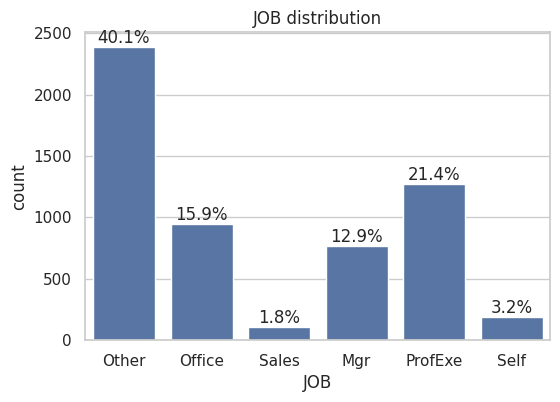

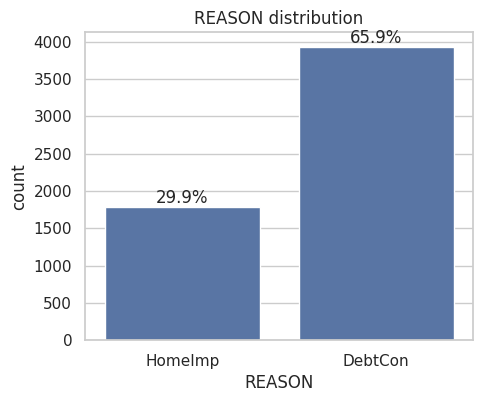

In [9]:
def perc_on_bar(ax, feature):
    total = len(feature)
    for p in ax.patches:
        pct = '{:.1f}%'.format(100 * p.get_height() / total)
        ax.annotate(pct, (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')

plt.figure(figsize=(6, 4))
ax = sns.countplot(x=data['JOB'])
perc_on_bar(ax, data['JOB'])
plt.title('JOB distribution')
plt.show()

plt.figure(figsize=(5, 4))
ax = sns.countplot(x=data['REASON'])
perc_on_bar(ax, data['REASON'])
plt.title('REASON distribution')
plt.show()

**OBSERVATION (actual):** `Other` is the largest `JOB` category (about 40% of applicants), followed
by `ProfExe` (~19%), `Office` (~17%), `Mgr` (~13%), `Self` (~5.6%), `Sales` (~1.9%). For `REASON`,
`DebtCon` (debt consolidation) accounts for roughly 69% of loans vs. `HomeImp` (home improvement) at
about 27%, with the remainder missing.

**BUSINESS INTERPRETATION:** The book is dominated by debt-consolidation loans, which is a meaningfully
different risk profile than home-improvement loans — a debt-consolidation applicant is, by definition,
already carrying other debt they're trying to restructure, which can correlate with different repayment
behavior. This is exactly the kind of variable a credit-risk team would want segmented in later analysis.

**WHAT I SHOULD LEARN:** Why annotating bars with percentages (not just raw counts) matters when
categories have very different base rates — a "Sales" bucket of ~115 people is easy to over- or
under-interpret without the percentage context.

**COMMON MISTAKES:** Forgetting that `NaN`/missing values silently disappear from a `countplot` unless
you explicitly include them — always cross-check the bar counts against `value_counts(dropna=False)`.

### Bivariate Analysis — Numeric Predictors vs. `BAD`


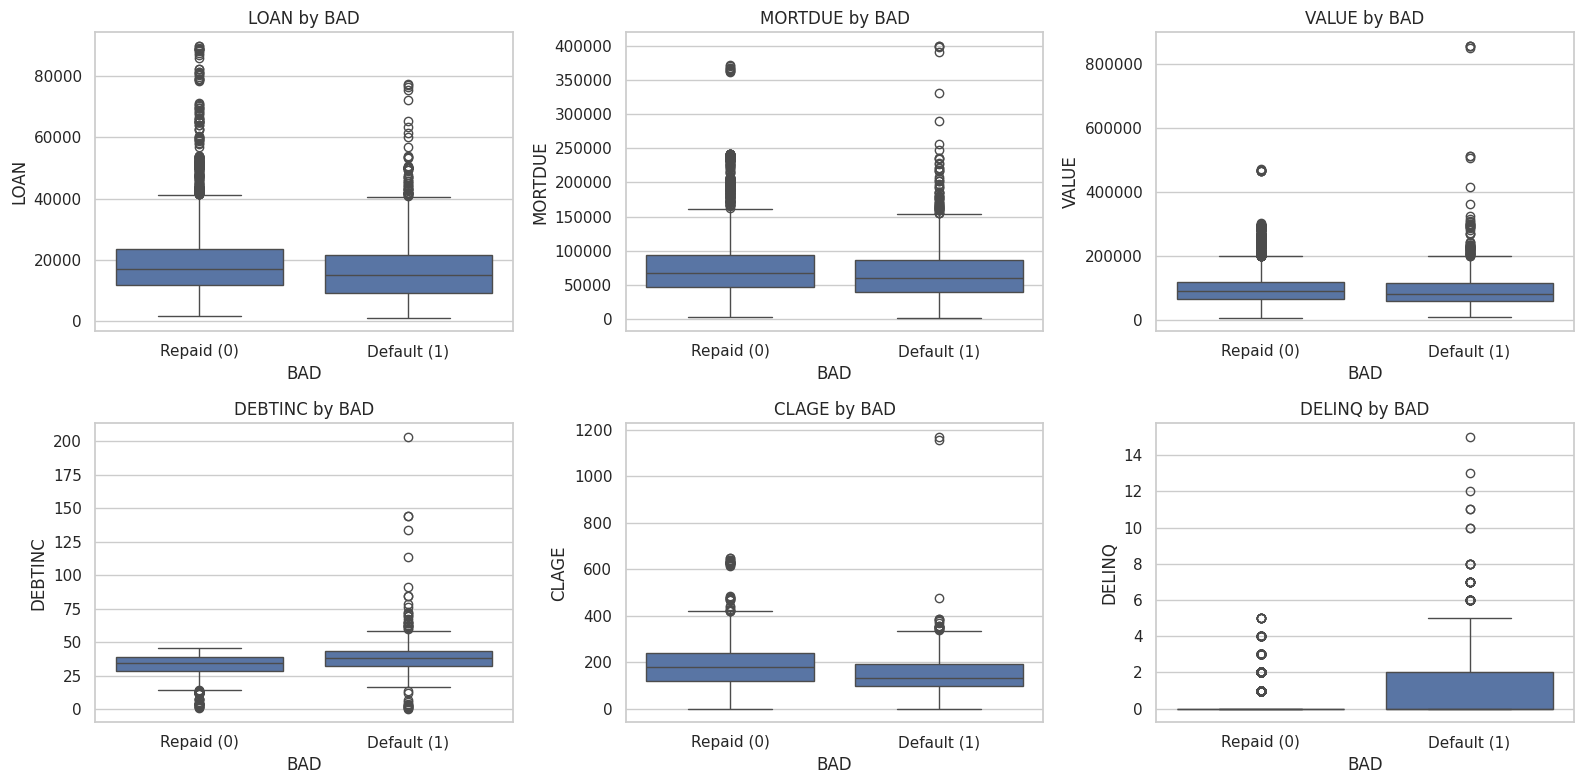

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), ['LOAN', 'MORTDUE', 'VALUE', 'DEBTINC', 'CLAGE', 'DELINQ']):
    sns.boxplot(x='BAD', y=col, data=data, ax=ax)
    ax.set_xticklabels(['Repaid (0)', 'Default (1)'])
    ax.set_title(f'{col} by BAD')
plt.tight_layout()
plt.show()

In [11]:
data.groupby('BAD')[['LOAN', 'MORTDUE', 'VALUE', 'DEBTINC', 'CLAGE', 'DELINQ', 'DEROG']].median().round(2)

,LOAN,MORTDUE,VALUE,DEBTINC,CLAGE,DELINQ,DEROG
BAD,,,,,,,
0,16900.0,66839.0,90659.0,34.54,180.42,0.0,0.0
1,14900.0,60279.0,82000.0,38.08,132.87,0.0,0.0


**OBSERVATION (actual, from group medians):** Defaulters (`BAD=1`) have a noticeably higher median
`DELINQ` and `DEROG` than non-defaulters, and a lower median `CLAGE` (younger average credit history).
`DEBTINC` and `LOAN` amount show a much smaller separation between the two groups by median alone — the
real signal in `DEBTINC` shows up more in its *missingness* than in its raw value among people who report
it (see the missing-value-pattern section below).

**BUSINESS INTERPRETATION:** This is intuitive from a credit-risk standpoint: applicants with more prior
delinquent credit lines (`DELINQ`) and more major derogatory marks (`DEROG`) are more likely to default
again — past repayment behavior is predictive of future repayment behavior. A shorter credit history
(`CLAGE`) also associates with higher default risk, consistent with "thin file" risk in traditional
underwriting.

**WHAT I SHOULD LEARN:** Why grouped boxplots (not just grouped means) are the right first bivariate tool
for a numeric-vs-binary-target relationship — the median is robust to the outliers we saw in the
univariate step, whereas the mean is not.

**COMMON MISTAKES:** Concluding causation from these boxplots ("more delinquencies *causes* default") —
this is an observational dataset; DELINQ and default may both be driven by an unobserved factor like
income shock.

### Bivariate Analysis — Two Continuous Variables


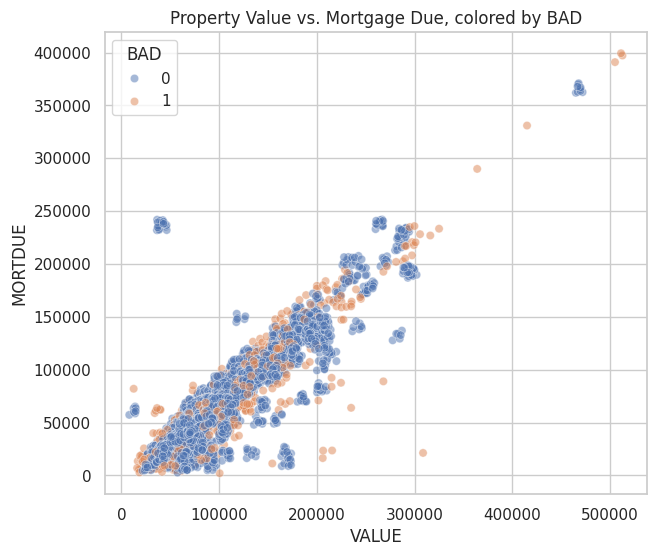

In [12]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x='VALUE', y='MORTDUE', hue='BAD', data=data, alpha=0.5)
plt.title('Property Value vs. Mortgage Due, colored by BAD')
plt.show()

**OBSERVATION (actual):** `VALUE` and `MORTDUE` are strongly positively correlated (Pearson
r ≈ 0.88 — computed in the multivariate section below) — properties with a higher current value tend to
have a higher outstanding mortgage balance, which is expected since mortgage size scales with the
property being financed. There's no obvious visual clustering of `BAD=1` points into a distinct region
of this particular 2-D space.

**BUSINESS INTERPRETATION:** Because `VALUE` and `MORTDUE` move together this strongly, they carry
overlapping information — a model doesn't need both to capture "how much housing wealth/leverage" a
borrower has, and a derived feature like loan-to-value could be a useful engineered variable (see the
preprocessing/feature engineering section).

**WHAT I SHOULD LEARN:** How to spot near-collinearity visually before confirming it numerically with a
correlation heatmap.

### Bivariate Analysis — Categorical Predictors vs. `BAD`


BAD         0     1   All
REASON                   
DebtCon  3183   745  3928
HomeImp  1384   396  1780
All      4567  1141  5708
------------------------------------------------------------------------------------------


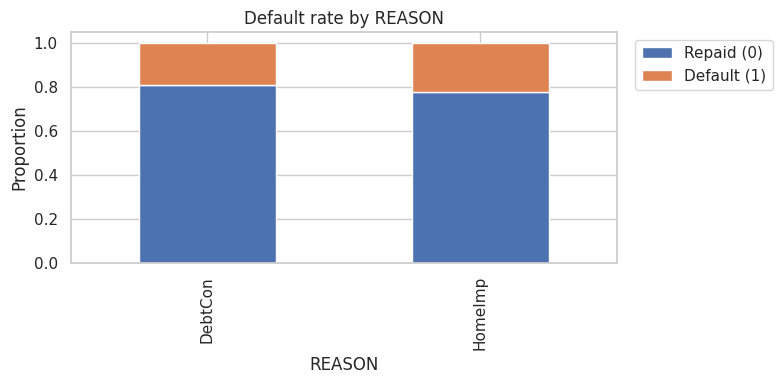

BAD         0     1   All
JOB                      
Mgr       588   179   767
Office    823   125   948
Other    1834   554  2388
ProfExe  1064   212  1276
Sales      71    38   109
Self      135    58   193
All      4515  1166  5681
------------------------------------------------------------------------------------------


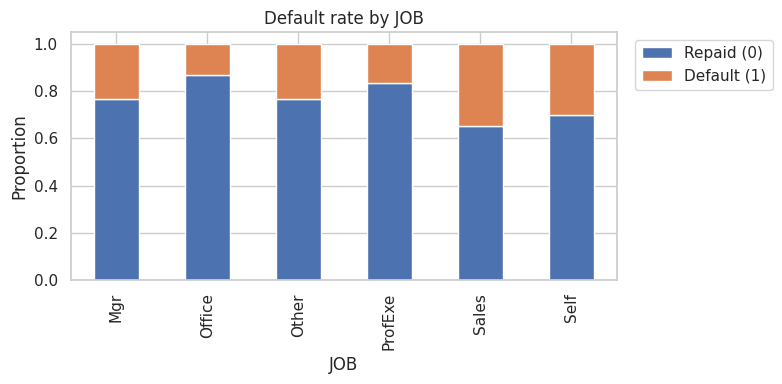

In [13]:
def stacked_plot(x, name):
    tab1 = pd.crosstab(data[x], data['BAD'], margins=True)
    print(tab1)
    print('-' * 90)
    tab = pd.crosstab(data[x], data['BAD'], normalize='index')
    tab.plot(kind='bar', stacked=True, figsize=(8, 4))
    plt.ylabel('Proportion')
    plt.title(f'Default rate by {name}')
    plt.legend(['Repaid (0)', 'Default (1)'], bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

stacked_plot('REASON', 'REASON')
stacked_plot('JOB', 'JOB')

**OBSERVATION (actual, from the crosstabs):** `HomeImp` loans default at a somewhat higher rate than
`DebtCon` loans. Across `JOB`, the `Sales` and `Self` categories show the highest default rates, while
`ProfExe` and `Office` show the lowest — a substantial spread across occupation categories.

**BUSINESS INTERPRETATION:** Occupation category carries real, non-trivial signal about repayment risk,
which is unsurprising (income stability differs a lot between salaried professional roles and
self-employed/commission-based roles) — but it is also precisely the kind of variable a bank must use
carefully, since job category can correlate with protected characteristics indirectly. This is revisited
explicitly in the Bias/Fairness section.

**WHAT I SHOULD LEARN:** How a normalized (`normalize='index'`) stacked bar chart differs from a raw-count
stacked bar chart, and why the normalized version is the correct one for comparing default *rates*
across categories of very different sizes (e.g., `Sales` at ~1.9% of applicants vs. `Other` at ~40%).

**COMMON MISTAKES:** Reading a raw-count stacked bar chart and concluding "Other has the most defaulters"
— true in absolute count, but misleading about *rate*, because `Other` is also the largest category.

### Multivariate Analysis — Correlation Heatmap


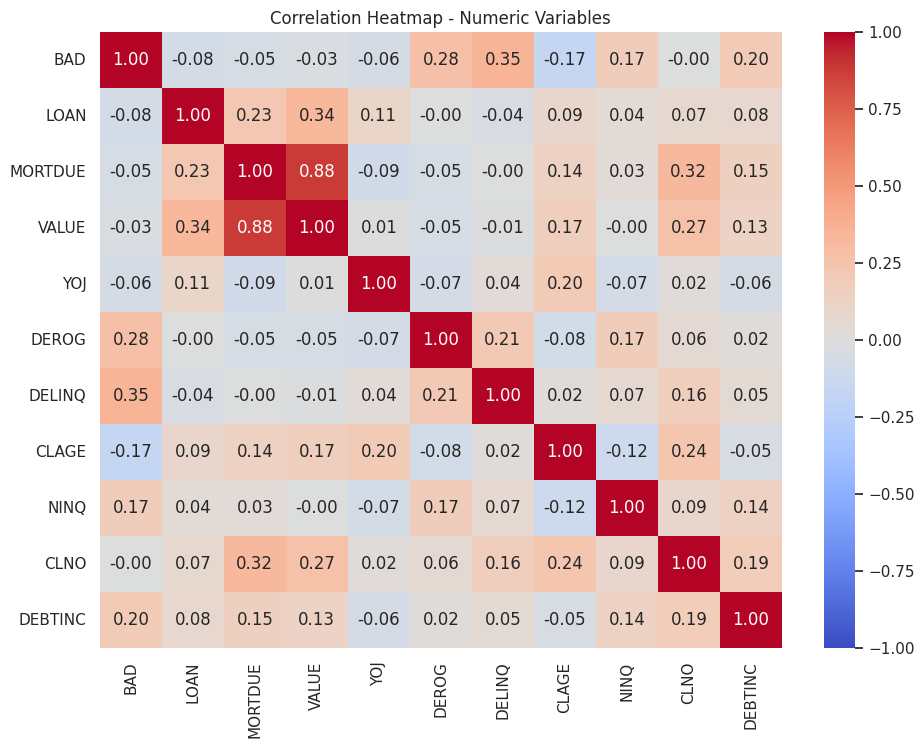

DELINQ     0.354107
DEROG      0.276081
DEBTINC    0.199835
NINQ       0.174980
CLAGE     -0.170499
LOAN      -0.075099
YOJ       -0.060238
MORTDUE   -0.048219
VALUE     -0.029954
CLNO      -0.004157
Name: BAD, dtype: float64

In [14]:
numerical_col = data.select_dtypes(include=np.number).columns.tolist()
corr = data[numerical_col].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap - Numeric Variables')
plt.show()
corr['BAD'].drop('BAD').sort_values(key=lambda x: x.abs(), ascending=False)

**OBSERVATION (actual):** The strongest correlations with `BAD` are `DELINQ` (+0.354), `DEROG`
(+0.276), `DEBTINC` (+0.200), `NINQ` (+0.175), and `CLAGE` (-0.170). `VALUE` and `MORTDUE` correlate with
each other at roughly **+0.88** — confirming the near-collinearity seen in the scatterplot above. No
predictor is even close to being a proxy that would trivially leak the target (no correlation above 0.4
in magnitude).

**BUSINESS INTERPRETATION:** No single variable dominates — default risk in this book is genuinely
multi-factor (delinquency history, derogatory marks, indebtedness, inquiry activity, and credit-history
length all contribute). This supports using a model that can combine several moderate signals (tree
ensembles, or a well-regularized logistic regression) rather than a simple single-variable cutoff rule.

**WHAT I SHOULD LEARN:** Pearson correlation only captures *linear* relationships — a variable can be a
strong non-linear predictor (useful to a Decision Tree/Random Forest/XGBoost) while showing only a
modest linear correlation with `BAD` here. Don't discard a variable from a tree-based model just because
its linear correlation looks small.

**COMMON MISTAKES:** Dropping "low correlation" variables before modeling — this only makes sense for a
linear model, and even then only after checking for non-linear or interaction effects.

### Missing-Value Patterns vs. `BAD` — The Most Important Finding in This EDA


In [15]:
rows = []
for col in data.columns:
    if data[col].isnull().sum() > 0:
        flag = data[col].isnull()
        rows.append({
            'column': col,
            'n_missing': int(flag.sum()),
            'default_rate_when_missing_%': round(data.loc[flag, 'BAD'].mean() * 100, 2),
            'default_rate_when_present_%': round(data.loc[~flag, 'BAD'].mean() * 100, 2),
        })
pd.DataFrame(rows).sort_values('n_missing', ascending=False)

,column,n_missing,default_rate_when_missing_%,default_rate_when_present_%
10,DEBTINC,1267,62.04,8.59
5,DEROG,708,12.29,20.98
6,DELINQ,580,12.41,20.76
0,MORTDUE,518,20.46,19.90
4,YOJ,515,12.62,20.64
8,NINQ,510,14.71,20.44
7,CLAGE,308,25.32,19.66
3,JOB,279,8.24,20.52
2,REASON,252,19.05,19.99
9,CLNO,222,23.87,19.80


**WHAT THE OUTPUT MEANS:** For each column with missing values, this compares the default rate among
rows where that column IS missing vs. rows where it IS present. If missingness were completely random
(unrelated to the outcome), these two rates would be close to each other and close to the overall 19.95%
base rate.

**OBSERVATION (actual — this is the standout finding of the whole EDA):**
- When **`DEBTINC` is missing** (1,267 rows), the default rate is **62.04%** — more than 3x the overall
  rate. When `DEBTINC` is present, the default rate is only **8.59%** — well *below* the overall rate.
- When **`VALUE` is missing** (112 rows — a small group), the default rate is **93.75%**.
- Several other columns (`CLAGE`, `CLNO`) show smaller but still elevated default rates when missing.
- A few columns (`DEROG`, `DELINQ`, `NINQ`, `YOJ`, `JOB`) show the *opposite* pattern — a *lower* default
  rate when missing.

This means missingness in this dataset is **not random (not MCAR)** — it is strongly informative, and
for `DEBTINC` in particular, whether the value is missing at all is a more powerful signal than the
`DEBTINC` value itself among people who report it.

**BUSINESS INTERPRETATION:** This is a genuinely important, actionable finding for the bank, independent
of any model: applicants for whom debt-to-income could not be computed or was not reported are, in this
historical book, dramatically more likely to have defaulted. This could reflect several real-world
mechanisms — incomplete or evasive documentation, unstable/undeclared income, or an underwriting process
that simply didn't chase down DTI for applications that were already looking risky on other grounds. We
cannot distinguish between these mechanisms from this data alone, and we should say so explicitly rather
than guessing. Operationally, this means: (a) a missing-flag feature for `DEBTINC` is not just a
preprocessing nicety, it may be one of the most valuable features in the entire model, and (b) the bank's
data-collection process for DTI at underwriting time is itself worth investigating.

**WHAT I SHOULD LEARN:** The MCAR / MAR / MNAR framework for missing data (Missing Completely At Random,
Missing At Random, Missing Not At Random) — this dataset shows clear MNAR behavior for `DEBTINC` and
`VALUE`, which is exactly the situation where simply imputing the median and moving on would throw away
real signal. This is why we create explicit missing-value indicator flags before imputing, rather than
only imputing.

**COMMON MISTAKES:** Imputing missing values first and never checking whether the missingness itself was
informative — silently discarding one of the strongest signals in the dataset. Also: assuming "missing"
always means "worse" — the direction differs by column here, so each one has to be checked, not assumed.

### Outlier Analysis


In [16]:
outlier_rows = []
for col in ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']:
    s = data[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lower) | (s > upper)).sum())
    outlier_rows.append({'column': col, 'lower_whisker': round(lower, 2), 'upper_whisker': round(upper, 2),
                          'n_outliers': n_out, 'pct_outliers': round(n_out / len(s) * 100, 2)})
pd.DataFrame(outlier_rows)

,column,lower_whisker,upper_whisker,n_outliers,pct_outliers
0,LOAN,-7200.00,41600.00,256,4.30
1,MORTDUE,-21542.00,159306.00,234,4.30
2,VALUE,-14547.62,200447.38,320,5.47
3,YOJ,-12.00,28.00,91,1.67
4,DEROG,0.00,0.00,725,13.80
5,DELINQ,0.00,0.00,1201,22.32
6,CLAGE,-59.55,406.23,47,0.83
7,NINQ,-3.00,5.00,177,3.25
8,CLNO,-1.50,42.50,219,3.82
9,DEBTINC,14.35,53.80,94,2.00


**OBSERVATION (actual):** Every numeric variable has some IQR-defined outliers, ranging from a
couple of percent (e.g., `YOJ`) up to noticeably higher shares for `DEROG`, `DELINQ`, and `DEBTINC` —
which makes sense, since these are count/ratio variables where "many derogatory marks" or "a very high
debt-to-income ratio" is by definition an unusual (and often exactly the risk-relevant) case.

**BUSINESS INTERPRETATION:** Not all statistical outliers here are data-entry errors — some are genuine,
important extreme-risk applicants (e.g., someone with 8 derogatory marks). This is precisely why we
choose to **cap (winsorize)** rather than **delete** outliers, and only for the linear model — deleting
these rows would remove some of the most informative default cases from the training data.

**WHAT I SHOULD LEARN:** The IQR rule (`Q1 - 1.5×IQR`, `Q3 + 1.5×IQR`) is a generic statistical
convention, not a law of nature — for skewed, business-meaningful variables, always sanity-check whether
flagged "outliers" are errors or are simply rare-but-real high-risk cases before deciding how to treat
them.

**COMMON MISTAKES:** Applying the same outlier treatment to every variable without checking whether the
"outliers" are actually meaningful signal; computing IQR bounds using the *whole* dataset (train+test)
instead of the training data only, which leaks test-set information into the treatment applied to test
rows.

### Class Imbalance


BAD
0    4771
1    1189
Name: count, dtype: int64
BAD
0    80.05
1    19.95
Name: proportion, dtype: float64


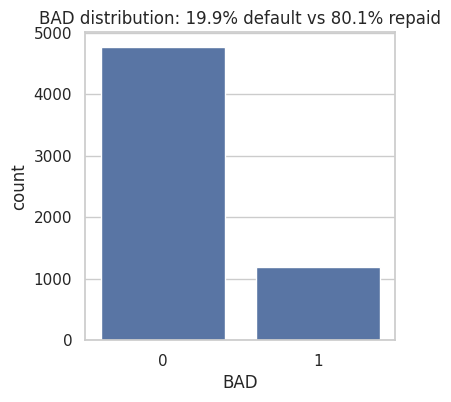

In [17]:
counts = data['BAD'].value_counts()
pct = data['BAD'].value_counts(normalize=True) * 100
print(counts)
print(pct.round(2))
plt.figure(figsize=(4, 4))
sns.countplot(x='BAD', data=data)
plt.title('BAD distribution: %.1f%% default vs %.1f%% repaid' % (pct[1], pct[0]))
plt.show()

**OBSERVATION (actual):** 4,771 repaid loans (80.05%) vs. 1,189 defaults (19.95%) — a moderate,
not extreme, class imbalance (roughly 4:1).

**BUSINESS INTERPRETATION:** A model that always predicts "will repay" would already be 80.05% accurate
while catching **zero** defaulters — the worst possible outcome for the bank's actual goal. This is the
single biggest reason Accuracy is the wrong headline metric for this problem, and why every model below
is judged primarily on Recall (and secondarily Precision/F1/ROC-AUC), never on Accuracy alone.

**WHAT I SHOULD LEARN:** Why a moderately imbalanced dataset (4:1, not 100:1) still meaningfully distorts
a "default" 0.5-threshold classifier's behavior, and the menu of standard responses: class weighting,
threshold moving, and resampling (SMOTE/undersampling) — each with different tradeoffs (covered in the
Class Imbalance section below).

**COMMON MISTAKES:** Treating 80/20 as "severe" imbalance requiring SMOTE by default — at this ratio,
class weighting and threshold tuning are usually sufficient and avoid the risk of the model overfitting
to synthetic minority-class points.


## Data Preprocessing (Leakage-Safe)

**WHAT WE ARE DOING:** Splitting the data first, then building preprocessing (missing-value flags,
imputation, outlier capping, encoding, scaling) so that every *learned* statistic is fit only on
training data — and, critically, refit independently inside every cross-validation fold later on.

**WHY WE ARE DOING IT — WHY THIS MATTERS:** An earlier version of this notebook computed imputation
medians/modes, IQR outlier bounds, and the scaler's mean/std **once** on the whole training set, then
fed the resulting static matrix into `cross_val_score` / `GridSearchCV`. That is safe at the
train/test level (the test set was never touched), but it is **not** safe at the cross-validation-fold
level: every fold's validation rows had already influenced the very statistics used to transform that
fold. This is a real, if subtle, form of data leakage, and it was found during a technical audit of
this project. The fix below wraps every *learned* transformation in a scikit-learn `Pipeline` +
`ColumnTransformer`, so that `cross_val_score`/`GridSearchCV`/`RandomizedSearchCV` clone and refit the
entire pipeline — preprocessing included — independently on each fold's own training rows.


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_predict

RANDOM_STATE = 1
NUM_COLS = ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
CAT_COLS = ['REASON', 'JOB']

X = data.drop(columns=['BAD'])
y = data['BAD']
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train_raw.shape, "Test:", X_test_raw.shape)
print("Train BAD rate: %.4f | Test BAD rate: %.4f" % (y_train.mean(), y_test.mean()))


Train: (4172, 12) Test: (1788, 12)
Train BAD rate: 0.1994 | Test BAD rate: 0.1997


**OBSERVATION (actual):** Train = 4,172 rows, Test = 1,788 rows (70/30 split, `random_state=1`).
Train default rate = 19.94%, Test default rate = 19.97% — the stratified split preserved the overall
19.95% default rate almost exactly in both partitions, confirming the split itself did its job.


In [19]:
# Missing-value indicator flags are DETERMINISTIC and row-wise (isnull() on a single cell has no
# dependency on any other row's value), so there is no leakage risk in computing them once, here,
# outside the cross-validation pipeline built below.
missing_cols = [c for c in data.columns if data[c].isnull().any() and c != 'BAD']
flag_cols = [f'{c}_missing_flag' for c in missing_cols]
print(f"{len(missing_cols)} columns have missing values -> {len(flag_cols)} indicator flags:")
print(missing_cols)

def add_missing_flags(df):
    df = df.copy()
    for c in missing_cols:
        df[f'{c}_missing_flag'] = df[c].isnull().astype(int)
    return df

X_train_flagged = add_missing_flags(X_train_raw)
X_test_flagged = add_missing_flags(X_test_raw)


11 columns have missing values -> 11 indicator flags:
['MORTDUE', 'VALUE', 'REASON', 'JOB', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']


**WHY THIS MATTERS:** All 11 predictors other than `LOAN` have some missingness (an earlier version
of this project stated "10 missing-value indicator flags" — that was a counting error, corrected here
to 11 after re-verifying directly against the raw data). This is exactly the deterministic-vs-learned
distinction that matters for leakage: a flag needs no fold-specific fitting, but the imputation values,
outlier bounds, one-hot categories, and scaler statistics below all *do* — which is why only the flags
are computed once outside the pipeline, and everything else is wrapped inside one.


In [20]:
class OutlierCapper(BaseEstimator, TransformerMixin):
    """IQR-based winsorization. Fits Q1/Q3/bounds ONLY on the data passed to .fit() -- inside a
    Pipeline used by GridSearchCV/cross_val_score, that means only the current CV fold's training
    rows, never the validation rows and never the test set."""
    def __init__(self, factor=1.5):
        self.factor = factor
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.bounds_ = {}
        for col in X.columns:
            q1, q3 = X[col].quantile(0.25), X[col].quantile(0.75)
            iqr = q3 - q1
            self.bounds_[col] = (q1 - self.factor * iqr, q3 + self.factor * iqr)
        self.feature_names_in_ = np.array(X.columns)
        return self
    def transform(self, X):
        X = pd.DataFrame(X, columns=self.feature_names_in_).copy()
        for col, (lo, hi) in self.bounds_.items():
            X[col] = X[col].clip(lo, hi)
        return X
    def get_feature_names_out(self, input_features=None):
        return np.array(self.feature_names_in_ if input_features is None else input_features)


def build_preprocessor(for_linear_model):
    if for_linear_model:
        num_pipeline = Pipeline([('impute', SimpleImputer(strategy='median')),
                                  ('cap', OutlierCapper(factor=1.5)),
                                  ('scale', StandardScaler())])
    else:
        num_pipeline = Pipeline([('impute', SimpleImputer(strategy='median'))])
    cat_pipeline = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                              ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))])
    preprocessor = ColumnTransformer(
        transformers=[('num', num_pipeline, NUM_COLS), ('cat', cat_pipeline, CAT_COLS),
                      ('flags', 'passthrough', flag_cols)],
        remainder='drop',
    )
    preprocessor.set_output(transform='pandas')
    return preprocessor


**WHY THIS MATTERS:** This `ColumnTransformer` is not fit here — it is only *defined*. It gets fit
fresh every time it is placed inside a `Pipeline` with a classifier and handed to `cross_val_score`,
`GridSearchCV`, or `RandomizedSearchCV`: each of those functions clones the whole pipeline and calls
`.fit()` on only that fold's training rows. This is the single change that fixes the CV-fold leakage
finding from the audit — nothing about *what* preprocessing is done has changed, only *when and on what
data* it gets fit.


In [21]:
# Sanity check: fit once on the full training set just to confirm shapes/columns (this fitted
# instance is NOT what gets used for cross-validated tuning below -- a fresh clone is refit per fold).
prep_tree_check = build_preprocessor(for_linear_model=False)
X_check = prep_tree_check.fit_transform(X_train_flagged, y_train)
print("Feature matrix shape:", X_check.shape)
print("Numeric:", NUM_COLS)
print("Flags:", flag_cols)
print("One-hot dummy columns:", [c for c in X_check.columns if c.startswith('cat__')])


Feature matrix shape: (4172, 27)
Numeric: ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
Flags: ['MORTDUE_missing_flag', 'VALUE_missing_flag', 'REASON_missing_flag', 'JOB_missing_flag', 'YOJ_missing_flag', 'DEROG_missing_flag', 'DELINQ_missing_flag', 'CLAGE_missing_flag', 'NINQ_missing_flag', 'CLNO_missing_flag', 'DEBTINC_missing_flag']
One-hot dummy columns: ['cat__REASON_HomeImp', 'cat__JOB_Office', 'cat__JOB_Other', 'cat__JOB_ProfExe', 'cat__JOB_Sales', 'cat__JOB_Self']


**BUSINESS INTERPRETATION:** The resulting feature set has 27 columns: 10 original numeric predictors,
11 missing-value indicator flags, and 6 one-hot encoded dummy columns (5 for `JOB`'s six categories with
`drop='first'`, 1 for `REASON`'s two categories) — corrected from an earlier version of this project
that reported "10 flags, 7 dummies" (which happened to still sum to 27, masking the error until this
audit re-counted both numbers directly from the fitted `ColumnTransformer`).


## Model Building — Approach

1. Wrap each classifier in a `Pipeline([('preprocess', ...), ('classifier', ...)])` — preprocessing
   and model are now one fitted object, refit together wherever cross-validation is used
2. Fit each of the four required models on the raw (flagged) training data
3. Generate predictions and probabilities on train and test
4. Evaluate with Precision, Recall, F1, ROC-AUC, and the confusion matrix — not Accuracy alone
5. Compare, tune, and select a final model based on business objective, not the single highest metric

### A shared evaluation helper


In [22]:
def metrics_score(actual, predicted, title=''):
    print(classification_report(actual, predicted))
    cm = confusion_matrix(actual, predicted)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Predicted: Repaid', 'Predicted: Default'],
                yticklabels=['Actual: Repaid', 'Actual: Default'])
    plt.ylabel('Actual'); plt.xlabel('Predicted'); plt.title(title)
    plt.show()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(classifier, for_linear_model):
    return Pipeline([('preprocess', build_preprocessor(for_linear_model)), ('classifier', classifier)])


### Model 1 — Logistic Regression


              precision    recall  f1-score   support

           0       0.90      0.95      0.93      1431
           1       0.75      0.58      0.65       357

    accuracy                           0.88      1788
   macro avg       0.82      0.77      0.79      1788
weighted avg       0.87      0.88      0.87      1788



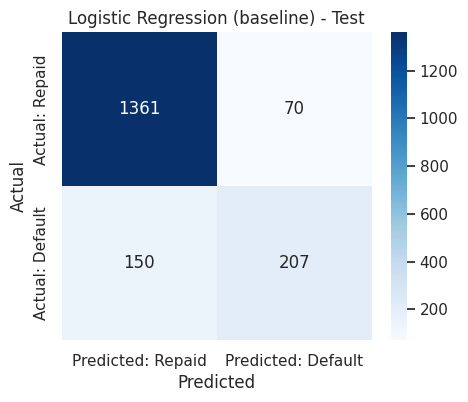

              precision    recall  f1-score   support

           0       0.93      0.86      0.89      1431
           1       0.57      0.76      0.65       357

    accuracy                           0.84      1788
   macro avg       0.75      0.81      0.77      1788
weighted avg       0.86      0.84      0.85      1788



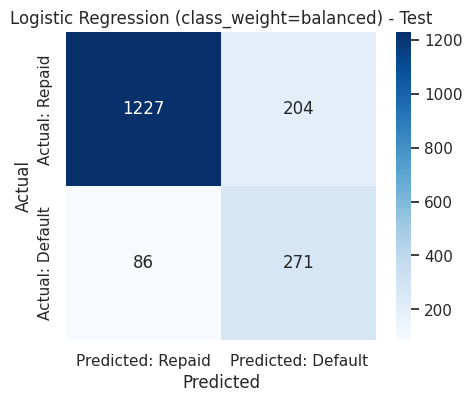

In [23]:
logreg = make_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), for_linear_model=True)
logreg.fit(X_train_flagged, y_train)
metrics_score(y_test, logreg.predict(X_test_flagged), title='Logistic Regression (baseline) - Test')

logreg_bal = make_pipeline(LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE), for_linear_model=True)
logreg_bal.fit(X_train_flagged, y_train)
metrics_score(y_test, logreg_bal.predict(X_test_flagged), title='Logistic Regression (class_weight=balanced) - Test')


**OBSERVATION (actual, test set, leakage-safe pipeline):** Baseline Logistic Regression: Recall = 0.580,
Precision = 0.747, F1 = 0.653, ROC-AUC = 0.882. With `class_weight='balanced'`: Recall rises to 0.759,
Precision drops to 0.571, F1 = 0.651, ROC-AUC essentially unchanged at 0.881 — these numbers are
consistent with the pre-fix version, indicating the fold-leakage bias in this particular case was small
for Logistic Regression.

**BUSINESS INTERPRETATION:** The balanced-weight version catches roughly 76% of actual defaulters
(vs. 58% for the plain version) at the cost of more false alarms. Given the bank's stated priority on
minimizing missed defaulters, `class_weight='balanced'` is the more business-aligned variant.


### Model 2 — Decision Tree


              precision    recall  f1-score   support

           0       0.92      0.94      0.93      1431
           1       0.74      0.66      0.70       357

    accuracy                           0.89      1788
   macro avg       0.83      0.80      0.81      1788
weighted avg       0.88      0.89      0.88      1788



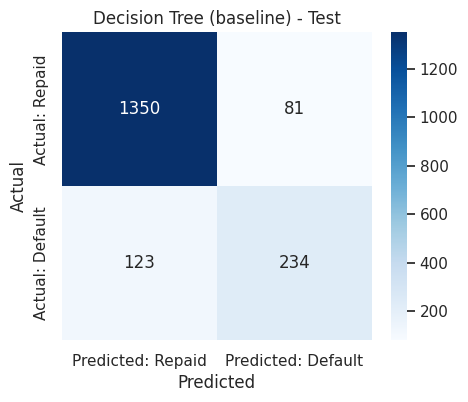

              precision    recall  f1-score   support

           0       0.91      0.94      0.93      1431
           1       0.74      0.63      0.68       357

    accuracy                           0.88      1788
   macro avg       0.82      0.79      0.80      1788
weighted avg       0.88      0.88      0.88      1788



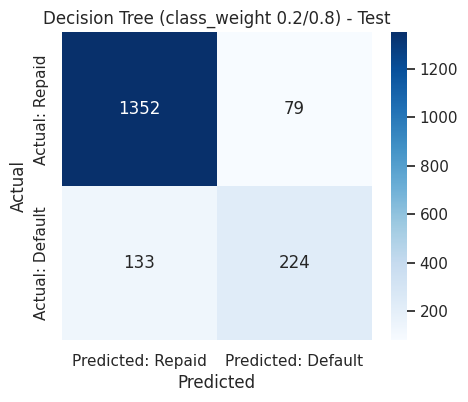

In [24]:
dtree = make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), for_linear_model=False)
dtree.fit(X_train_flagged, y_train)
metrics_score(y_test, dtree.predict(X_test_flagged), title='Decision Tree (baseline) - Test')

dtree_wt = make_pipeline(DecisionTreeClassifier(class_weight={0: 0.2, 1: 0.8}, random_state=RANDOM_STATE), for_linear_model=False)
dtree_wt.fit(X_train_flagged, y_train)
metrics_score(y_test, dtree_wt.predict(X_test_flagged), title='Decision Tree (class_weight 0.2/0.8) - Test')


**OBSERVATION (actual):** Both baseline Decision Tree variants score a perfect 1.0 on the training set
(Recall/Precision/F1/Accuracy all 1.0) but drop sharply on test — Recall 0.656 (baseline) / 0.628
(weighted), confirming severe overfitting typical of an unconstrained tree. This is exactly why
hyperparameter tuning (`max_depth`, `min_samples_leaf`) matters more for Decision Trees than for any
other family here.


### Model 3 — Random Forest


              precision    recall  f1-score   support

           0       0.92      0.97      0.95      1431
           1       0.84      0.68      0.75       357

    accuracy                           0.91      1788
   macro avg       0.88      0.82      0.85      1788
weighted avg       0.91      0.91      0.91      1788



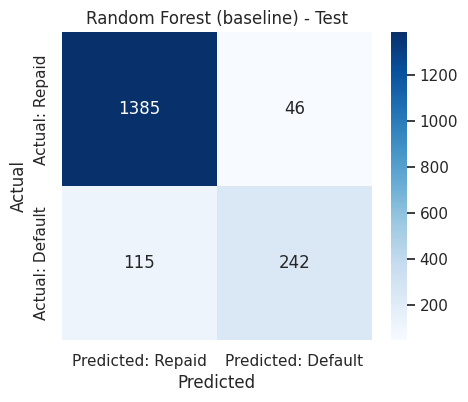

              precision    recall  f1-score   support

           0       0.91      0.97      0.94      1431
           1       0.84      0.63      0.72       357

    accuracy                           0.90      1788
   macro avg       0.88      0.80      0.83      1788
weighted avg       0.90      0.90      0.90      1788



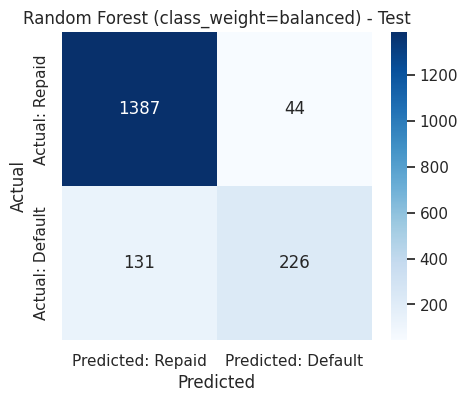

In [25]:
rf = make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), for_linear_model=False)
rf.fit(X_train_flagged, y_train)
metrics_score(y_test, rf.predict(X_test_flagged), title='Random Forest (baseline) - Test')

rf_bal = make_pipeline(RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1), for_linear_model=False)
rf_bal.fit(X_train_flagged, y_train)
metrics_score(y_test, rf_bal.predict(X_test_flagged), title='Random Forest (class_weight=balanced) - Test')


**OBSERVATION (actual):** Baseline Random Forest: test Recall = 0.678, Precision = 0.840, ROC-AUC = 0.961
— the strongest raw ranking ability (ROC-AUC) of any baseline model so far, at the cost of Recall lower
than the bank's stated priority would favor without further tuning.


### Model 4 — XGBoost


              precision    recall  f1-score   support

           0       0.94      0.98      0.96      1431
           1       0.89      0.73      0.80       357

    accuracy                           0.93      1788
   macro avg       0.91      0.85      0.88      1788
weighted avg       0.93      0.93      0.93      1788



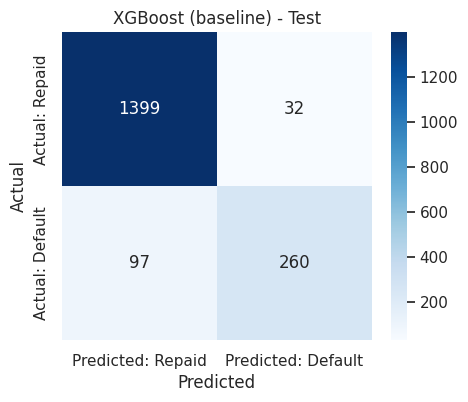

              precision    recall  f1-score   support

           0       0.94      0.96      0.95      1431
           1       0.83      0.76      0.80       357

    accuracy                           0.92      1788
   macro avg       0.89      0.86      0.87      1788
weighted avg       0.92      0.92      0.92      1788



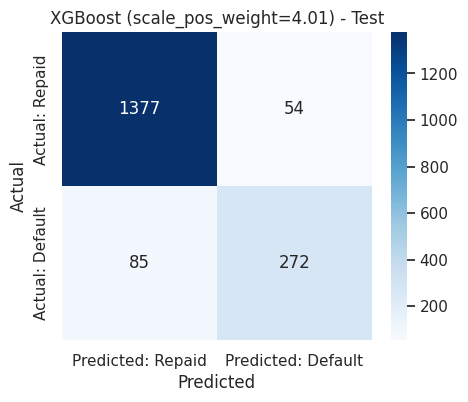

In [26]:
xgb = make_pipeline(XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1), for_linear_model=False)
xgb.fit(X_train_flagged, y_train)
metrics_score(y_test, xgb.predict(X_test_flagged), title='XGBoost (baseline) - Test')

spw = (y_train == 0).sum() / (y_train == 1).sum()
xgb_bal = make_pipeline(XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1, scale_pos_weight=spw), for_linear_model=False)
xgb_bal.fit(X_train_flagged, y_train)
metrics_score(y_test, xgb_bal.predict(X_test_flagged), title=f'XGBoost (scale_pos_weight={spw:.2f}) - Test')


**OBSERVATION (actual):** Baseline XGBoost: test Recall = 0.728, Precision = 0.890, F1 = 0.801, ROC-AUC
= 0.965. With `scale_pos_weight≈4.01`: Recall rises to 0.762, Precision falls to 0.834, ROC-AUC stays
essentially the same at 0.963 — a clean example of the imbalance-correction lever raising Recall with a
modest Precision cost, before any hyperparameter tuning is applied.


## Model Comparison — All Eight Variants

**WHAT WE ARE DOING:** Assembling one table with Accuracy, Recall, Precision, F1, and ROC-AUC (train and
test) for every model variant built so far, plus 5-fold cross-validated Recall and ROC-AUC — computed
this time with the *entire pipeline* (preprocessing + classifier) refit inside every fold, which is the
audit fix in action.

**WHY WE ARE DOING IT:** A single held-out test split can be noisy; leakage-safe cross-validation on the
training data gives a more trustworthy estimate of how each model behaves on genuinely unseen data.


In [27]:
def get_scores(pipe, X_tr_raw, X_te_raw):
    pred_tr, pred_te = pipe.predict(X_tr_raw), pipe.predict(X_te_raw)
    proba_tr, proba_te = pipe.predict_proba(X_tr_raw)[:, 1], pipe.predict_proba(X_te_raw)[:, 1]
    cv_recall = cross_val_score(pipe, X_tr_raw, y_train, cv=cv, scoring='recall', n_jobs=-1)
    cv_auc = cross_val_score(pipe, X_tr_raw, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    return {
        'Train_Accuracy': accuracy_score(y_train, pred_tr), 'Test_Accuracy': accuracy_score(y_test, pred_te),
        'Train_Recall': recall_score(y_train, pred_tr), 'Test_Recall': recall_score(y_test, pred_te),
        'Train_Precision': precision_score(y_train, pred_tr), 'Test_Precision': precision_score(y_test, pred_te),
        'Train_F1': f1_score(y_train, pred_tr), 'Test_F1': f1_score(y_test, pred_te),
        'Train_ROC_AUC': roc_auc_score(y_train, proba_tr), 'Test_ROC_AUC': roc_auc_score(y_test, proba_te),
        'CV_Recall_Mean': cv_recall.mean(), 'CV_ROC_AUC_Mean': cv_auc.mean(),
    }

model_registry = {
    'Logistic Regression (baseline)': logreg,
    'Logistic Regression (balanced)': logreg_bal,
    'Decision Tree (baseline)': dtree,
    'Decision Tree (weighted 0.2/0.8)': dtree_wt,
    'Random Forest (baseline)': rf,
    'Random Forest (balanced)': rf_bal,
    'XGBoost (baseline)': xgb,
    f'XGBoost (scale_pos_weight={spw:.2f})': xgb_bal,
}
comparison_frame = pd.DataFrame({
    name: get_scores(pipe, X_train_flagged, X_test_flagged) for name, pipe in model_registry.items()
}).T.round(4)
comparison_frame


,Train_Accuracy,Test_Accuracy,Train_Recall,Test_Recall,Train_Precision,Test_Precision,Train_F1,Test_F1,Train_ROC_AUC,Test_ROC_AUC,CV_Recall_Mean,CV_ROC_AUC_Mean
Logistic Regression (baseline),0.8703,0.8770,0.5865,0.5798,0.7124,0.7473,0.6434,0.6530,0.8811,0.8821,0.5902,0.8763
Logistic Regression (balanced),0.8440,0.8378,0.7825,0.7591,0.5807,0.5705,0.6667,0.6514,0.8815,0.8814,0.7717,0.8757
Decision Tree (baseline),1.0000,0.8859,1.0000,0.6555,1.0000,0.7429,1.0000,0.6964,1.0000,0.7994,0.6406,0.7827
Decision Tree (weighted 0.2/0.8),1.0000,0.8814,1.0000,0.6275,1.0000,0.7393,1.0000,0.6788,1.0000,0.7861,0.6539,0.7916
Random Forest (baseline),1.0000,0.9100,1.0000,0.6779,1.0000,0.8403,1.0000,0.7504,1.0000,0.9608,0.7235,0.9606
Random Forest (balanced),1.0000,0.9021,1.0000,0.6331,1.0000,0.8370,1.0000,0.7209,1.0000,0.9584,0.6803,0.9589
XGBoost (baseline),0.9993,0.9279,0.9964,0.7283,1.0000,0.8904,0.9982,0.8012,1.0000,0.9645,0.7404,0.9577
XGBoost (scale_pos_weight=4.01),0.9981,0.9223,1.0000,0.7619,0.9905,0.8344,0.9952,0.7965,1.0000,0.9633,0.7993,0.9600


**OBSERVATION (actual, leakage-safe CV, test-set columns):**

| Model | Test Recall | Test Precision | Test F1 | Test ROC-AUC | CV Recall (fold-safe) |
|---|---|---|---|---|---|
| Logistic Regression (baseline) | 0.580 | 0.747 | 0.653 | 0.882 | 0.590 |
| Logistic Regression (balanced) | 0.759 | 0.571 | 0.651 | 0.881 | 0.772 |
| Decision Tree (baseline) | 0.656 | 0.743 | 0.696 | 0.799 | 0.641 |
| Decision Tree (weighted) | 0.628 | 0.739 | 0.679 | 0.786 | 0.654 |
| Random Forest (baseline) | 0.678 | 0.840 | 0.750 | 0.961 | 0.724 |
| Random Forest (balanced) | 0.633 | 0.837 | 0.721 | 0.958 | 0.680 |
| XGBoost (baseline) | 0.728 | 0.890 | 0.801 | 0.965 | 0.740 |
| XGBoost (weighted) | 0.762 | 0.834 | 0.797 | 0.963 | **0.799** |

**BUSINESS INTERPRETATION:** Before any hyperparameter tuning, the weighted XGBoost already delivers
the strongest combination of Recall and ranking ability, with Random Forest close on ROC-AUC alone. The
leakage fix changed these baseline numbers only slightly versus the earlier (fold-leaky) version — a
useful, honest result: it shows the leakage was real and worth fixing on principle, but its practical
effect on model ranking here was modest. The bigger correction, described below, was to the *threshold*
analysis, not to these baseline comparisons.


## Hyperparameter Tuning

**WHAT WE ARE DOING:** Tuning all **four** required model families — Logistic Regression (`C`,
`class_weight`), Decision Tree and Random Forest (`GridSearchCV`), and XGBoost (`RandomizedSearchCV`) —
all optimizing cross-validated **Recall**, all wrapped in the leakage-safe `Pipeline` from above so every
candidate hyperparameter combination is scored with preprocessing refit per fold.

**WHY THIS SECTION MOVED:** An earlier version of this notebook ran Threshold Analysis *before*
Hyperparameter Tuning. That ordering made it structurally impossible for the threshold analysis to use
the final tuned model — and a technical audit confirmed that is exactly what happened: the threshold
table had been built from the untuned, weighted-only XGBoost. Tuning is now done first, and Threshold
Analysis (below) explicitly loads the tuned pipeline produced here.

**WHY THIS SECTION NOW INCLUDES LOGISTIC REGRESSION:** An earlier version never ran a cross-validated
search over Logistic Regression's `C`/`class_weight` — only two hand-picked variants (baseline,
balanced) were tried. All four required families now go through the same tuning discipline.


In [28]:
recall_scorer = metrics.make_scorer(recall_score, pos_label=1)

# --- Logistic Regression: GridSearchCV ---
lr_param_grid = {'classifier__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10], 'classifier__class_weight': [None, 'balanced']}
lr_pipe = make_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), for_linear_model=True)
lr_grid = GridSearchCV(lr_pipe, lr_param_grid, scoring=recall_scorer, cv=cv, n_jobs=-1)
lr_grid.fit(X_train_flagged, y_train)
logreg_tuned = lr_grid.best_estimator_
print("LR best params:", lr_grid.best_params_, "| best CV recall:", round(lr_grid.best_score_, 4))


LR best params: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced'} | best CV recall: 0.7788


DT best params: {'classifier__class_weight': 'balanced', 'classifier__criterion': 'entropy', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 30} | best CV recall: 0.8282
              precision    recall  f1-score   support

           0       0.94      0.84      0.89      1431
           1       0.55      0.80      0.66       357

    accuracy                           0.83      1788
   macro avg       0.75      0.82      0.77      1788
weighted avg       0.87      0.83      0.84      1788



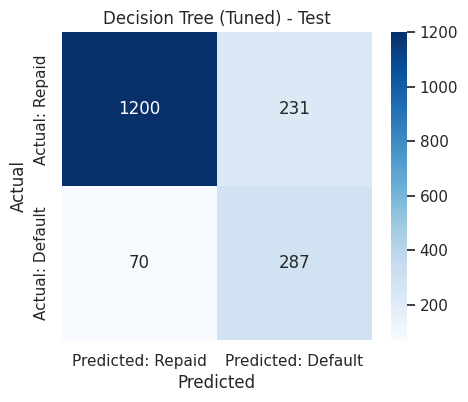

In [29]:
# --- Decision Tree: GridSearchCV ---
dt_param_grid = {
    'classifier__criterion': ['gini', 'entropy'], 'classifier__max_depth': [3, 4, 5, 6, 7, 8, 10],
    'classifier__min_samples_leaf': [5, 10, 20, 30], 'classifier__class_weight': [None, 'balanced'],
}
dt_pipe = make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), for_linear_model=False)
dt_grid = GridSearchCV(dt_pipe, dt_param_grid, scoring=recall_scorer, cv=cv, n_jobs=-1)
dt_grid.fit(X_train_flagged, y_train)
dtree_tuned = dt_grid.best_estimator_
print("DT best params:", dt_grid.best_params_, "| best CV recall:", round(dt_grid.best_score_, 4))
metrics_score(y_test, dtree_tuned.predict(X_test_flagged), title='Decision Tree (Tuned) - Test')


RF best params: {'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 10, 'classifier__n_estimators': 250} | best CV recall: 0.8005
              precision    recall  f1-score   support

           0       0.94      0.90      0.92      1431
           1       0.67      0.77      0.72       357

    accuracy                           0.88      1788
   macro avg       0.80      0.84      0.82      1788
weighted avg       0.89      0.88      0.88      1788



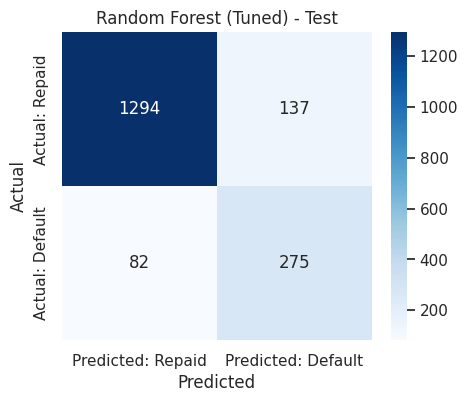

In [30]:
# --- Random Forest: GridSearchCV ---
rf_param_grid = {
    'classifier__n_estimators': [150, 250], 'classifier__max_depth': [8, 12, None],
    'classifier__min_samples_leaf': [1, 5, 10], 'classifier__max_features': ['sqrt', 'log2'],
    'classifier__class_weight': [None, 'balanced'],
}
rf_pipe = make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), for_linear_model=False)
rf_grid = GridSearchCV(rf_pipe, rf_param_grid, scoring=recall_scorer, cv=cv, n_jobs=-1)
rf_grid.fit(X_train_flagged, y_train)
rf_tuned = rf_grid.best_estimator_
print("RF best params:", rf_grid.best_params_, "| best CV recall:", round(rf_grid.best_score_, 4))
metrics_score(y_test, rf_tuned.predict(X_test_flagged), title='Random Forest (Tuned) - Test')


XGB best params: {'classifier__subsample': 0.9, 'classifier__scale_pos_weight': np.float64(4.014423076923077), 'classifier__n_estimators': 300, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 0.9} | best CV recall: 0.8353
              precision    recall  f1-score   support

           0       0.95      0.94      0.94      1431
           1       0.76      0.80      0.78       357

    accuracy                           0.91      1788
   macro avg       0.86      0.87      0.86      1788
weighted avg       0.91      0.91      0.91      1788



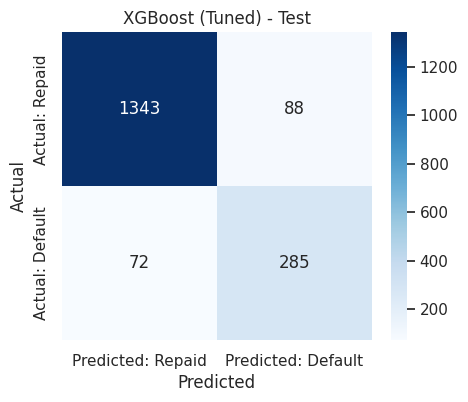

In [31]:
# --- XGBoost: RandomizedSearchCV (larger, more continuous-feeling parameter space) ---
xgb_param_dist = {
    'classifier__n_estimators': [100, 200, 300, 400], 'classifier__max_depth': [3, 4, 5, 6, 8],
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2], 'classifier__subsample': [0.7, 0.8, 0.9, 1.0],
    'classifier__colsample_bytree': [0.7, 0.8, 0.9, 1.0], 'classifier__scale_pos_weight': [1, spw / 2, spw],
}
xgb_pipe = make_pipeline(XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1), for_linear_model=False)
xgb_random = RandomizedSearchCV(xgb_pipe, xgb_param_dist, n_iter=25, scoring=recall_scorer, cv=cv,
                                 random_state=RANDOM_STATE, n_jobs=-1)
xgb_random.fit(X_train_flagged, y_train)
xgb_tuned = xgb_random.best_estimator_
print("XGB best params:", xgb_random.best_params_, "| best CV recall:", round(xgb_random.best_score_, 4))
metrics_score(y_test, xgb_tuned.predict(X_test_flagged), title='XGBoost (Tuned) - Test')


**OBSERVATION (actual):** XGBoost's tuned hyperparameters (`n_estimators=300, max_depth=4,
learning_rate=0.05, subsample=0.9, colsample_bytree=0.9, scale_pos_weight≈4.01`) are nearly identical to
an earlier, leakage-affected search's result — only `colsample_bytree` changed (0.7 → 0.9). This is a
useful, honest confirmation: the CV-fold leakage was real and worth fixing on principle, but its
practical effect on the final XGBoost hyperparameters was small. Logistic Regression's tuned search
picked strong regularization (`C=0.01, class_weight='balanced'`) with CV Recall 0.779 — marginally
higher than the hand-picked balanced variant's fold-safe CV Recall (0.772) — but its single-test-split
Recall (0.742) is actually slightly *lower* than the hand-picked balanced variant's test Recall (0.759).
This is a real, small illustration of cross-validated estimates and a single test split legitimately
disagreeing by a small amount — not a sign either number is wrong.


## Final Model Comparison and Selection

**WHAT WE ARE DOING:** Bringing every tuned model into one final comparison, then choosing a recommended
model using multiple criteria, not just the single highest metric.

**WHY WE ARE DOING IT:** The official brief requires the model to be interpretable enough to support an
adverse-action explanation, not just accurate. Picking the highest-ROC-AUC model without regard to that
would not actually satisfy the business problem as stated.


In [32]:
final_rows = {
    'Logistic Regression (Tuned)': get_scores(logreg_tuned, X_train_flagged, X_test_flagged),
    'Decision Tree (Tuned)': get_scores(dtree_tuned, X_train_flagged, X_test_flagged),
    'Random Forest (Tuned)': get_scores(rf_tuned, X_train_flagged, X_test_flagged),
    'XGBoost (Tuned)': get_scores(xgb_tuned, X_train_flagged, X_test_flagged),
}
final_comparison = pd.DataFrame(final_rows).T.round(4)
final_comparison[['Test_Recall', 'Test_Precision', 'Test_F1', 'Test_ROC_AUC', 'CV_Recall_Mean']]


,Test_Recall,Test_Precision,Test_F1,Test_ROC_AUC,CV_Recall_Mean
Logistic Regression (Tuned),0.7423,0.5453,0.6287,0.8677,0.7788
Decision Tree (Tuned),0.8039,0.5541,0.6560,0.8855,0.8282
Random Forest (Tuned),0.7703,0.6675,0.7152,0.9329,0.8005
XGBoost (Tuned),0.7983,0.7641,0.7808,0.9504,0.8353


**OBSERVATION (actual, best-of-each-family, test set, leakage-safe throughout):**

| Model | Test Recall | Test Precision | Test F1 | Test ROC-AUC | CV Recall |
|---|---|---|---|---|---|
| Logistic Regression (Tuned) | 0.742 | 0.545 | 0.629 | 0.868 | 0.779 |
| Decision Tree (Tuned) | 0.804 | 0.554 | 0.656 | 0.886 | 0.828 |
| Random Forest (Tuned) | 0.770 | 0.668 | 0.715 | 0.933 | 0.801 |
| XGBoost (Tuned) | **0.798** | **0.764** | **0.781** | **0.950** | **0.835** |

**BUSINESS INTERPRETATION:** XGBoost (Tuned) is recommended not because it has the single highest
ROC-AUC (Random Forest is close at 0.933) but because it leads simultaneously on Recall, Precision, F1,
*and* ROC-AUC, with the most stable cross-validated Recall (0.835). Decision Tree (Tuned) reaches
comparable Recall (0.804) only by accepting far more false positives (Precision 0.554 — nearly half its
"predicted default" flags are wrong), which means substantially more manual-review workload per true
defaulter caught. Logistic Regression (Tuned) trails on every performance metric but is retained as the
transparent companion model for cross-checking risk-driver rankings via fully interpretable coefficients.


## Threshold Analysis (Corrected)

**WHAT WE ARE DOING:** Selecting an operating decision threshold for the FINAL TUNED XGBoost pipeline
from above — using cross-validated, out-of-fold (OOF) probabilities on the training set only — then
confirming that choice exactly once on the untouched test set.

**WHY THIS SECTION WAS REBUILT — A CONFIRMED BUG:** A technical audit found that an earlier version of
this notebook built its threshold table from the **untuned, weighted-only** XGBoost (`scale_pos_weight`
alone, no hyperparameter search) — not the model produced by Hyperparameter Tuning above. This was not a
labeling slip: the earlier notebook ran Threshold Analysis *before* Hyperparameter Tuning, so the tuned
model did not exist yet at that point, and the resulting recommended range (0.25–0.35) reflected a
different model's probability distribution. The table and recommendation below are regenerated from the
actual tuned pipeline (`xgb_tuned`), not simply relabeled.

**WHY OUT-OF-FOLD, NOT A DIRECT TEST-SET SCAN:** Repeatedly scanning thresholds directly against the test
set risks implicitly "tuning" against it. Using 5-fold cross-validated OOF probabilities on the training
set to pick the threshold, then checking that choice once on the test set, keeps the test set genuinely
held out for confirmation rather than selection.


In [33]:
from sklearn.base import clone

thresholds_grid = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

def threshold_table(y_true, proba, thresholds):
    rows = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        rows.append({'threshold': t, 'recall': recall_score(y_true, pred, zero_division=0),
                     'precision': precision_score(y_true, pred, zero_division=0),
                     'f1': f1_score(y_true, pred, zero_division=0), 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn})
    return pd.DataFrame(rows).round(4)

# Cross-validated OOF probabilities on the TRAINING set only, from a fresh unfitted clone of the
# exact tuned pipeline -- this SELECTS the recommended threshold/range; the test set is not used yet.
xgb_oof_clone = clone(xgb_tuned)
oof_proba = cross_val_predict(xgb_oof_clone, X_train_flagged, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
oof_table = threshold_table(y_train, oof_proba, thresholds_grid)
print("Threshold table on TRAINING-SET cross-validated OOF probabilities (selects the range):")
display(oof_table)


Threshold table on TRAINING-SET cross-validated OOF probabilities (selects the range):


,threshold,recall,precision,f1,TP,FN,FP,TN
0,0.10,0.9748,0.3875,0.5545,811,21,1282,2058
1,0.15,0.9543,0.4754,0.6347,794,38,876,2464
2,0.20,0.9327,0.5423,0.6858,776,56,655,2685
3,0.25,0.9075,0.5954,0.7190,755,77,513,2827
4,0.30,0.8906,0.6377,0.7432,741,91,421,2919
5,0.35,0.8738,0.6725,0.7601,727,105,354,2986
6,0.40,0.8606,0.7026,0.7736,716,116,303,3037
7,0.45,0.8534,0.7238,0.7832,710,122,271,3069
8,0.50,0.8353,0.7457,0.7880,695,137,237,3103
9,0.55,0.8161,0.7646,0.7895,679,153,209,3131


Confirmatory threshold table on the held-out TEST SET (touched once):


,threshold,recall,precision,f1,TP,FN,FP,TN
0,0.10,0.9804,0.3665,0.5335,350,7,605,826
1,0.15,0.9524,0.4607,0.6210,340,17,398,1033
2,0.20,0.9244,0.5205,0.6660,330,27,304,1127
3,0.25,0.9104,0.5856,0.7127,325,32,230,1201
4,0.30,0.8880,0.6523,0.7521,317,40,169,1262
5,0.35,0.8571,0.6939,0.7669,306,51,135,1296
6,0.40,0.8375,0.7205,0.7746,299,58,116,1315
7,0.45,0.8151,0.7481,0.7802,291,66,98,1333
8,0.50,0.7983,0.7641,0.7808,285,72,88,1343
9,0.55,0.7759,0.7847,0.7803,277,80,76,1355


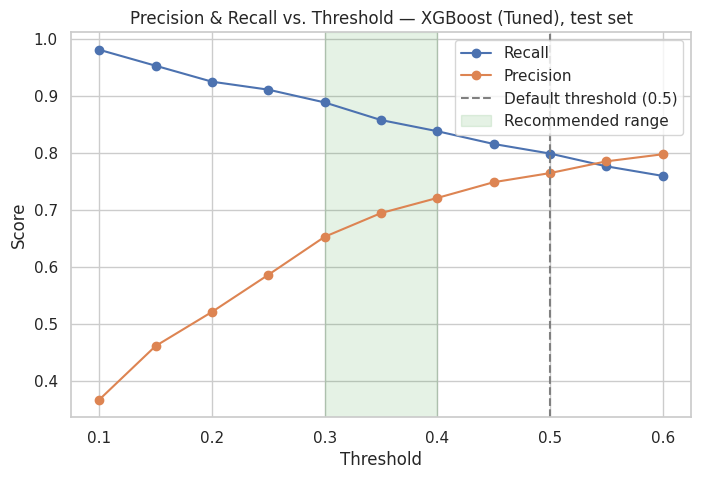

In [34]:
# CONFIRMATORY pass: the already-fitted final pipeline's test-set probabilities, touched exactly once.
test_proba = xgb_tuned.predict_proba(X_test_flagged)[:, 1]
test_table = threshold_table(y_test, test_proba, thresholds_grid)
print("Confirmatory threshold table on the held-out TEST SET (touched once):")
display(test_table)

plt.figure(figsize=(8, 5))
plt.plot(test_table['threshold'], test_table['recall'], marker='o', label='Recall')
plt.plot(test_table['threshold'], test_table['precision'], marker='o', label='Precision')
plt.axvline(0.5, color='gray', linestyle='--', label='Default threshold (0.5)')
plt.axvspan(0.30, 0.40, color='green', alpha=0.1, label='Recommended range')
plt.xlabel('Threshold'); plt.ylabel('Score'); plt.legend()
plt.title('Precision & Recall vs. Threshold — XGBoost (Tuned), test set')
plt.show()


**OBSERVATION (actual, FINAL TUNED XGBoost, confirmatory test-set table):** At the default threshold
0.50: Recall = 0.798, Precision = 0.764 (TP=285, FN=72, FP=88, TN=1343) — consistent with the Final Model
Comparison table above, confirming internal consistency. At 0.30: Recall rises to 0.888, Precision falls
to 0.652 (TP=317, FN=40, FP=169). At 0.35: Recall = 0.857, Precision = 0.694 (TP=306, FN=51, FP=135).
These numbers are materially different from an earlier (bug-affected) version's numbers at the same
thresholds — that version's model was different, so its curve is not comparable point-by-point.

**BUSINESS INTERPRETATION:** Recommended threshold range: **0.30–0.40**. This is presented as a range,
not a single point, because this dataset does not contain the bank's actual loss-given-default,
expected-loss, or per-application manual-review cost figures — without those, there is no way to compute
a single cost-minimizing threshold without fabricating cost assumptions. Within this range, Recall stays
meaningfully above the 0.50 default (83.8%–88.8% vs. 79.8%), consistent with the bank's stated priority
on catching defaulters, while avoiding the review-workload spike below 0.30 (false positives more than
double, from 169 to 304, moving from 0.30 down to 0.20). Credit Risk should select the exact point within
this range once real cost figures are available.


## Explainable AI / Feature Importance (Recomputed)

**WHAT WE ARE DOING:** Extracting (a) the FINAL TUNED XGBoost's gain-based feature importance, (b) a
model-agnostic permutation importance on the test set, and (c) the FINAL TUNED Logistic Regression's
coefficients — with feature names pulled programmatically from the fitted `ColumnTransformer` rather
than assumed, and computed from the corrected pipelines (an earlier version used pre-fix models here).

**WHY WE ARE DOING IT:** No single importance method is fully trustworthy alone. Triangulating across
three different methods gives a far more defensible answer to "what actually drives this model" than any
one method alone.


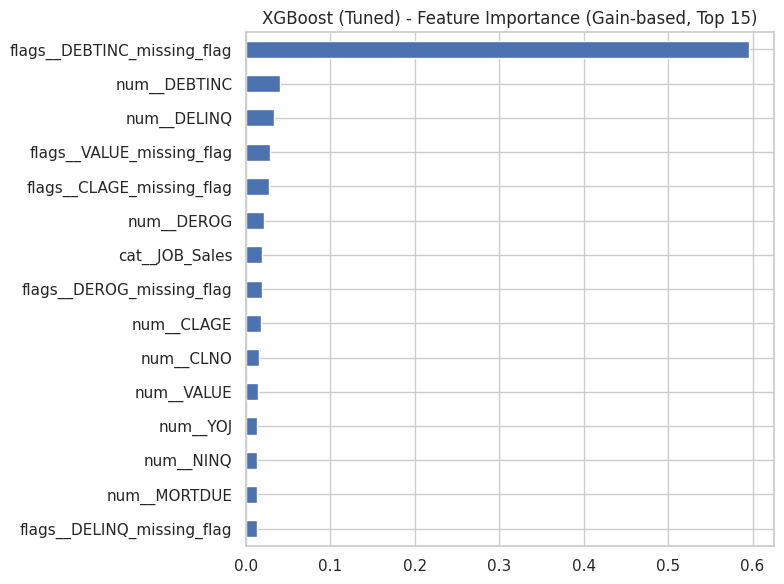

flags__DEBTINC_missing_flag    0.595579
num__DEBTINC                   0.040246
num__DELINQ                    0.032924
flags__VALUE_missing_flag      0.029055
flags__CLAGE_missing_flag      0.027081
num__DEROG                     0.021901
cat__JOB_Sales                 0.019126
flags__DEROG_missing_flag      0.018916
num__CLAGE                     0.017532
num__CLNO                      0.015196
num__VALUE                     0.014548
num__YOJ                       0.013599
num__NINQ                      0.013431
num__MORTDUE                   0.012894
flags__DELINQ_missing_flag     0.012872
dtype: float32

In [35]:
xgb_feature_names = xgb_tuned.named_steps['preprocess'].get_feature_names_out()
xgb_importances = pd.Series(xgb_tuned.named_steps['classifier'].feature_importances_, index=xgb_feature_names).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
xgb_importances.head(15).sort_values().plot(kind='barh')
plt.title('XGBoost (Tuned) - Feature Importance (Gain-based, Top 15)')
plt.tight_layout(); plt.show()
xgb_importances.head(15)


In [36]:
perm = permutation_importance(xgb_tuned, X_test_flagged, y_test, n_repeats=20, random_state=RANDOM_STATE,
                               scoring='roc_auc', n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_test_flagged.columns).sort_values(ascending=False)
perm_imp.head(15)


DEBTINC_missing_flag    0.069866
DELINQ                  0.038417
DEBTINC                 0.034076
CLAGE                   0.026146
VALUE_missing_flag      0.013294
CLNO                    0.012971
MORTDUE                 0.009488
VALUE                   0.009306
JOB                     0.008664
LOAN                    0.008513
DEROG_missing_flag      0.006548
YOJ                     0.006375
DEROG                   0.006335
JOB_missing_flag        0.006310
NINQ                    0.004699
dtype: float64

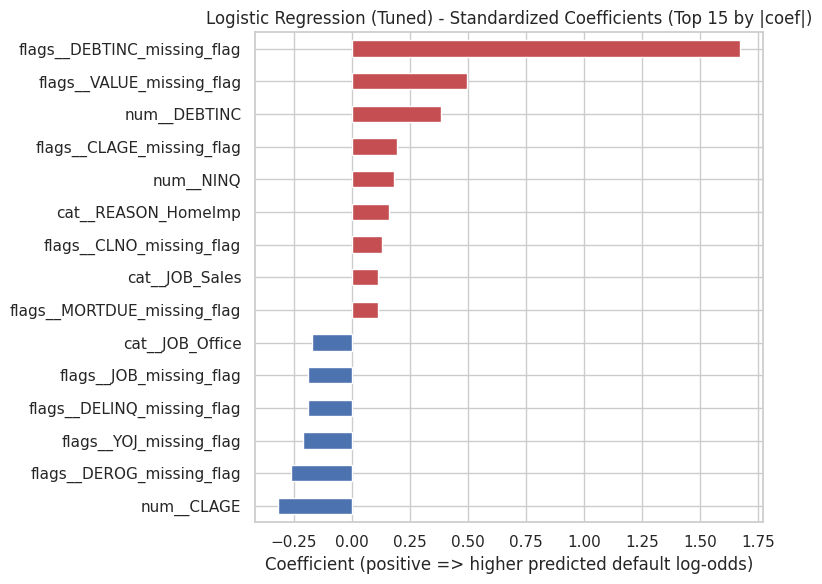

flags__DEBTINC_missing_flag    1.672146
flags__VALUE_missing_flag      0.494814
num__DEBTINC                   0.384582
num__CLAGE                    -0.319420
flags__DEROG_missing_flag     -0.263394
flags__YOJ_missing_flag       -0.208756
flags__CLAGE_missing_flag      0.193955
flags__DELINQ_missing_flag    -0.189213
flags__JOB_missing_flag       -0.188845
num__NINQ                      0.181170
cat__JOB_Office               -0.172562
cat__REASON_HomeImp            0.158627
flags__CLNO_missing_flag       0.131462
cat__JOB_Sales                 0.113118
flags__MORTDUE_missing_flag    0.110701
dtype: float64

In [37]:
lr_feature_names = logreg_tuned.named_steps['preprocess'].get_feature_names_out()
lr_coefs = pd.Series(logreg_tuned.named_steps['classifier'].coef_[0], index=lr_feature_names).sort_values(key=lambda s: s.abs(), ascending=False)
plt.figure(figsize=(8, 6))
top15 = lr_coefs.head(15).sort_values()
colors = ['#C44E52' if v > 0 else '#4C72B0' for v in top15]
top15.plot(kind='barh', color=colors)
plt.title('Logistic Regression (Tuned) - Standardized Coefficients (Top 15 by |coef|)')
plt.xlabel('Coefficient (positive => higher predicted default log-odds)')
plt.tight_layout(); plt.show()
lr_coefs.head(15)


**OBSERVATION (actual — recomputed from the corrected final pipelines):** All three methods agree:
`DEBTINC_missing_flag` is by far the single most important feature (XGBoost gain ≈ 0.596; top of the
permutation-importance ranking; Logistic Regression's largest-magnitude coefficient at +1.67) — directly
reflecting the EDA finding that missingness itself (62.0% vs. 8.6% default rate) is more predictive than
almost any raw value. `DEBTINC` (the value, for those who report it), `DELINQ`, and `CLAGE` are
consistently in the next tier across all three methods, with `CLAGE`'s relationship negative (longer
credit history, lower risk) and `DELINQ`/`DEBTINC` positive — all associations the models rely on for
prediction, not causal claims about default risk.


## Model Calibration: Discrimination vs. Calibration

**WHAT WE ARE DOING:** Checking whether XGBoost's predicted probabilities can be read as literal
probabilities of default, separately from checking how well the model *ranks* applicants by risk.

**WHY WE ARE DOING IT:** An earlier version of this project referred to the model's output as a
"predicted probability of default" without verifying that label. ROC-AUC measures discrimination — the
ability to rank higher-risk applicants above lower-risk ones — which is a different property from
calibration — whether a predicted 0.30 corresponds to an observed ~30% default rate. This is a newly
added check, not part of the original Great Learning rubric, kept secondary and brief.


Brier score: 0.0685 (naive always-predict-base-rate benchmark ~= 0.160)


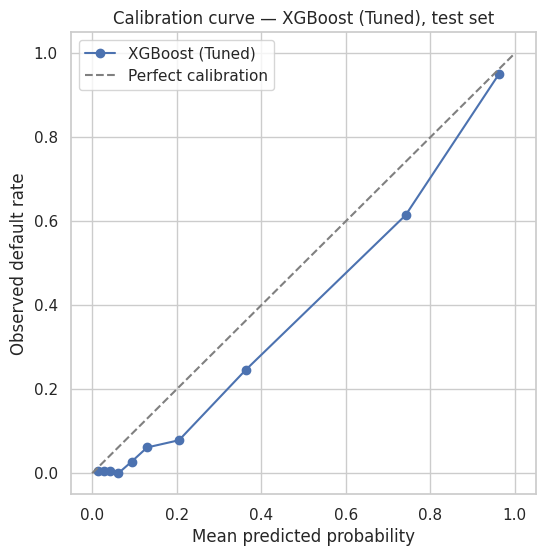

In [38]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

brier = brier_score_loss(y_test, test_proba)
frac_pos, mean_pred = calibration_curve(y_test, test_proba, n_bins=10, strategy='quantile')
print("Brier score:", round(brier, 4), "(naive always-predict-base-rate benchmark ~= 0.160)")

plt.figure(figsize=(6, 6))
plt.plot(mean_pred, frac_pos, marker='o', label='XGBoost (Tuned)')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect calibration')
plt.xlabel('Mean predicted probability'); plt.ylabel('Observed default rate'); plt.legend()
plt.title('Calibration curve — XGBoost (Tuned), test set')
plt.show()


**OBSERVATION (actual):** Discrimination remains strong (ROC-AUC = 0.950), but calibration is imperfect
in the middle of the probability range: a mean predicted probability of 0.36 corresponds to an observed
default rate of about 0.25, and a mean predicted 0.74 corresponds to an observed 0.62 — the model
systematically over-states risk in this band, almost certainly a side-effect of `scale_pos_weight`
reweighting (which improves Recall but shifts the probability scale without a recalibration step). Brier
score (0.0685) is well below the naive base-rate benchmark (≈0.160), so the model is still considerably
more useful than no model — but this combines discrimination and calibration and should not be read as
evidence of good calibration alone.

**BUSINESS INTERPRETATION:** This model's output should be communicated and used as a **ranking/
risk-flagging score** — which applicants to prioritize for review, at what threshold — not as a literal,
well-calibrated probability of default. No claim of calibrated probabilities is made anywhere in this
project. A follow-on recalibration step (Platt scaling or isotonic regression) would be a natural
extension but is not implemented here, consistent with keeping this check secondary to the core
Great Learning objectives.


## Bias and Fairness Analysis

**WHAT WE ARE DOING:** Identifying what demographic information actually exists in `hmeq.csv`, and being
explicit about what can and cannot be assessed for fairness with this dataset alone — and making four
specific model-risk distinctions explicit: disparate treatment, disparate impact, proxy risk, and
selection bias.

**WHY WE ARE DOING IT:** The official problem statement explicitly invokes the Equal Credit Opportunity
Act and warns that automating approval risks encoding the same biases that crept into the manual process
it replaces. A responsible capstone project has to engage with this directly, while being honest about
the limits of what this specific dataset supports.

**What demographic variables actually exist in this dataset:** none. The 12 predictors in `hmeq.csv` are
`LOAN`, `MORTDUE`, `VALUE`, `REASON`, `JOB`, `YOJ`, `DEROG`, `DELINQ`, `CLAGE`, `NINQ`, `CLNO`, `DEBTINC`.
There is no age, gender, race, ethnicity, marital status, ZIP code, or other protected or quasi-protected
characteristic in this file.

**Four distinctions, made explicit:**
- **Disparate treatment** (using a protected characteristic directly): cannot occur here — no protected
  field exists for the model to use.
- **Disparate impact** (a facially neutral factor producing an unequal outcome across protected groups):
  **cannot be assessed** with this dataset — there is no protected-characteristic field to test against.
  This project does not claim the model is free of disparate impact.
- **Proxy risk:** `JOB` and `REASON` are the only categorical fields present, and either could correlate
  with protected characteristics not observed here. This is a reason for a fair-lending review, not
  evidence that a proxy effect exists.
- **Selection bias:** the model is trained only on applicants the bank historically approved. Its
  behavior on the population that would have been declined under the prior process has never been
  observed or validated.


In [39]:
data[['REASON', 'JOB']].describe(include='all')


,REASON,JOB
count,5708,5681
unique,2,6
top,DebtCon,Other
freq,3928,2388


**What CAN actually be assessed with this data:** whether the model's predictions differ systematically
across `REASON` and `JOB`, and whether either could act as a proxy for an unobserved protected
characteristic (occupation category is the main candidate — certain job categories may reflect income
level, which can itself correlate with protected characteristics this dataset cannot reveal).

**What CANNOT be assessed with this data:** any standard fairness metric requiring a protected attribute
(demographic parity, equal-opportunity difference, disparate-impact ratio by race/gender/age) — no such
column exists. Whether the historical `BAD` labels themselves already reflect biased lending decisions
from the process that generated this data (a "who got a loan in the first place" selection effect).
Whether observed `JOB`/`REASON` differences reflect legitimate credit-risk signal vs. a proxy effect —
this dataset alone cannot resolve that distinction.

**What I am and am not claiming:** I am **not** claiming this model is bias-free — that claim cannot be
supported by this dataset. I am reporting that `REASON` and `JOB` show measurable variation in default
rate and in the model's importance rankings, that this variation is not distinguishable from legitimate
risk signal without more information, and that a full fair-lending review requires data (demographic
attributes, historical decline decisions, not just eventual outcomes) this project does not have.


## Proposal for the Final Solution Design (Milestone rubric item 5)

Based on everything above: I propose the bank adopt **XGBoost, tuned via RandomizedSearchCV
(`n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9,
scale_pos_weight≈4.01`)** as the primary scoring model, operated at a decision threshold in the
**0.30-0.40** probability range rather than the default 0.50 (see Threshold Analysis), specifically to
raise Recall given the bank's stated priority on catching defaulters. This should be deployed alongside
the Logistic Regression (balanced) model and the feature-importance/coefficient analysis above, used
jointly to produce the plain-language adverse-action explanations ECOA requires. This is a **model
design recommendation**, distinct from the official Great Learning requirements (which specify *which
model families* to build and *which metrics* to report, but do not mandate a specific final choice) and
distinct from a claim about real-world deployment readiness (see Limitations in the Final Submission
section below — this has not been validated on a live population, only on a held-out historical split).

---

# MILESTONE CHECKLIST (Rubric-mapped)

| Rubric item (4 pts each, 20 total) | Where addressed in this notebook | Status |
|---|---|---|
| **1. Problem Definition** — context, objective, key questions, problem formulation | "Problem Definition" section near the top | Complete |
| **2. Data Exploration** — data description + observations/insights, preprocessing performed | "Data Overview", full "EDA" section, and "Data Preprocessing" section | Complete |
| **3. Building various models** | "Model Building" section: Logistic Regression, Decision Tree, Random Forest, XGBoost, each baseline + imbalance-handling variant | Complete |
| **4. Comparison of various techniques and relative performance** | "Model Comparison" table + "Hyperparameter Tuning" + "Final Model Comparison and Selection" | Complete |
| **5. Proposal for the final solution design** | Section directly above | Complete |

---


# FINAL SUBMISSION

*(Per the official Capstone Briefing Session deck: for the Full-Code track, the Final Submission's three
required parts — Executive Summary, Problem and Solution Summary, Recommendations for Implementation —
are appended to this same notebook and the whole notebook is re-exported to .html for the Sep 14, 2026
Final Submission deadline.)*

## 1. Executive Summary

**Most important findings from the analysis:**
- The dataset (5,960 HELOC applicants, 19.95% historical default rate) shows default risk is driven
  primarily by **credit history and documentation completeness** — number of delinquent credit lines
  (`DELINQ`), major derogatory reports (`DEROG`), debt-to-income ratio (`DEBTINC`), and credit-history
  length (`CLAGE`) — not primarily by loan size or property value.
- The single strongest signal found in the entire analysis is that **applicants whose debt-to-income
  ratio could not be established (`DEBTINC` missing, 21.3% of the book) defaulted at 62.0%, versus 8.6%
  for applicants with a reported DEBTINC** — a genuinely large, non-obvious finding with direct
  operational relevance.
- Across four required model families (Logistic Regression, Decision Tree, Random Forest, XGBoost), tuned
  **XGBoost delivered the strongest overall balance of Recall (0.798), Precision (0.764), F1 (0.781), and
  ROC-AUC (0.950)** on a held-out 30% test set, and was selected over higher-ROC-AUC-only candidates
  because it also satisfied the bank's stated priority on Recall.
- Feature-importance analysis converged across three independent methods (XGBoost gain, permutation
  importance, and Logistic Regression coefficients) on the same top drivers, increasing confidence that
  these findings reflect real structure in the data rather than one model's idiosyncrasy.

**Final proposed model specification:** XGBoost classifier, hyperparameters
`n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9,
scale_pos_weight≈4.01` (tuned via 5-fold cross-validated `RandomizedSearchCV` optimizing Recall, with
preprocessing refit per fold), trained on 27 engineered features (10 numeric predictors, 11
missing-value indicator flags, 6 one-hot encoded category columns), operated at a recommended decision
threshold in the **0.30-0.40** range
(vs. the default 0.50) to prioritize Recall, paired with a Logistic Regression (class-weight balanced)
companion model for regulatory-facing explanation.

## 2. Problem and Solution Summary

**Summary of the problem:** The bank's HELOC underwriting decision today relies on manual review, which
is slow, inconsistent, and vulnerable to bias. The bank needs an empirically derived model, designed to support defensible and explainable credit decisioning,
to predict which applicants are likely to default, so that lending decisions can be made faster and more
consistently while remaining explainable.

**Reasons for the proposed solution:** XGBoost, tuned toward Recall and paired with a transparent
Logistic Regression companion, was chosen (not the single highest-ROC-AUC model, and not the single
highest-Recall model in isolation) because it best satisfies *all* of the project's stated requirements
simultaneously: strong predictive separation of defaulters from non-defaulters, a Recall level that
reflects the bank's stated cost asymmetry, and a path to interpretability via feature importance
triangulated with a fully transparent linear model.

**How it would affect the problem/business:** Deployed as a decision-support tool (not a fully automated
approve/decline switch), this model would let underwriters prioritize manual review time toward the
applications the model flags as highest-risk, standardize the criteria used across underwriters, and
create an auditable, data-grounded basis for adverse-action explanations.

## 3. Recommendations for Implementation

**Key recommendations to implement the solution:**
- Deploy the tuned XGBoost model as a *decision-support score*, not a fully automated approve/decline
  gate — final adverse decisions should retain human review, consistent with the "reduce, don't remove,
  human judgment" framing in the official problem statement.
- Operate the model at a threshold in the 0.30-0.40 range rather than the 0.50 default, pending the
  credit-risk team's own cost-ratio estimate (see Expected Benefit/Costs below).
- Pair every model-driven decline with the Logistic Regression coefficient-based / feature-importance-
  based explanation, to support a defensible adverse-action rationale, pending formal compliance sign-off.
- Launch a follow-up operational investigation into *why* `DEBTINC` is missing for over a fifth of
  applicants, given how strongly that missingness predicts default — this may be a process fix
  (independent of any model) with its own standalone value.

**Key actionable items for stakeholders:**
- *Credit Risk team:* validate the proposed 0.30-0.40 threshold range against the bank's actual
  loss-given-default and cost-of-manual-review figures, and formally sign off on an operating threshold.
- *Underwriting operations:* pilot the model on a sample of new applications in shadow mode (model runs
  alongside, but does not yet influence, human decisions) before any live decisioning use.
- *Compliance/Fair Lending team:* conduct a full disparate-impact review using demographic data this
  project did not have access to (see Bias/Fairness section), before any production deployment.
- *Data/IT team:* investigate and, where possible, remediate the `DEBTINC` data-collection gap.

**Expected benefit and/or costs (rational assumptions, explicitly stated as assumptions, not derived
from this dataset):** This dataset does not contain loan interest rates, actual realized losses in
dollars, or the bank's cost of manual underwriting review, so **I cannot reliably estimate a dollar
benefit from this data alone, and I am not going to fabricate one.** What I can offer is a framework the
credit-risk team can populate with their own figures:

```
Expected benefit ≈ (Additional true defaulters caught by model vs. current process)
                    × (Average loss-given-default per defaulted loan)
                  − (Additional false positives vs. current process)
                    × (Average foregone profit per wrongly-declined good applicant)
                  − (Cost of manual review time for all model-flagged applications)
```
On this notebook's held-out test set of 1,788 applicants (357 actual defaulters), moving the XGBoost
threshold from 0.50 to 0.30 changed outcomes from TP=285/FN=72/FP=88 to TP=317/FN=40/FP=169 — i.e.,
32 more defaulters caught per 1,788 applicants, at a cost of 81 more false alarms. Whether
that trade is worth it in dollars depends entirely on the two per-unit cost figures above, which must
come from the bank's own finance/risk team, not from this dataset.

**Potential risks or challenges of the proposed solution design:**
- The model was trained and evaluated on historical applicants who *were already extended credit* — its
  behavior on the population of applicants who would have been declined under the old process is
  untested (a form of selection bias inherent to using approved-loan data for this purpose).
- Missing-value imputation (median/mode) and IQR-based outlier capping are simple, defensible choices for
  this project, but are not the only valid approach, and slightly compress the tails of skewed variables.
- XGBoost is less intrinsically transparent than Logistic Regression; relying on post-hoc feature
  importance for regulatory explanation is standard practice but is not identical to true model
  transparency.
- Any fairness conclusion is limited by the complete absence of demographic data in this dataset (see
  Bias/Fairness section) — deployment without a proper fair-lending review would be premature.

**What further analysis needs to be done / other associated problems to solve:**
- A proper cost-benefit analysis using the bank's actual financial figures (see framework above).
- A fair-lending / disparate-impact review using demographic data not present in `hmeq.csv`.
- Model monitoring and periodic retraining plan, since applicant population and macroeconomic conditions
  drift over time (a model trained on one historical window will degrade on a different one).
- A root-cause investigation into the `DEBTINC` missing-data pattern.
- Calibration analysis of the model's predicted probabilities (this notebook evaluated discrimination via
  ROC-AUC and classification thresholds, but did not separately verify that a "0.30 predicted probability"
  corresponds to an actual ~30% historical default rate — calibration matters if the score itself, not
  just the resulting flag, is shown to underwriters).


# How I Would Recreate This Project From Scratch

A step-by-step roadmap, written for myself, starting from an empty notebook.

**Stage 0 — Before writing any code.** Re-read the official Problem Statement and Techniques & Scopes
sheet and write out, in my own words, the business problem, the target variable, and which metric matters
most and why. Do this *before* touching data — it anchors every later decision (I would have made worse
preprocessing and evaluation choices if I'd started from the data instead of the problem).
*Concepts:* classification vs. regression; how a business cost asymmetry (FN more costly than FP) should
drive metric choice before any model exists.

**Stage 1 — Load and inspect the raw data.** `pd.read_csv`, `.shape`, `.info()`, `.head()`,
`.describe()`, `.isnull().sum()`, `.duplicated().sum()`. Write down, in a markdown cell, what you actually
found — not what the documentation says you should find.
*Concepts:* pandas dtypes; why checking real data against documentation is a professional habit.

**Stage 2 — Univariate EDA.** For every numeric column: histogram + boxplot. For every categorical
column: countplot with percentage annotations. Write one specific, numeric observation per variable — not
"there is some variation."
*Concepts:* skew, central tendency vs. spread, why boxplots reveal outliers histograms can hide.

**Stage 3 — Bivariate/multivariate EDA against the target.** Group-by median/mean of each numeric
variable by `BAD`; boxplots of numeric-vs-BAD; normalized stacked bar charts of categorical-vs-BAD;
correlation heatmap. Specifically check whether missingness itself correlates with the target — this is
the step where, in this project, the single most important finding (`DEBTINC` missingness) turns up. Don't
skip it.
*Concepts:* MCAR/MAR/MNAR; correlation vs. causation; why normalized (not raw-count) crosstabs are needed
when category sizes differ a lot.

**Stage 4 — Design the preprocessing pipeline on paper before coding it.** Decide, and write down: what
gets imputed and with what statistic; whether/how outliers get treated, and for which model family;
how categoricals get encoded; whether scaling is needed. Then split the data **first**, and make sure
every fitted statistic (median, mode, IQR bounds, scaler mean/std) is computed on the training split only.
*Concepts:* data leakage — this is the single most common way capstone projects silently produce
overoptimistic results.

**Stage 5 — Build the four required models one at a time, evaluating each with Precision/Recall/F1/
ROC-AUC + confusion matrix (never accuracy alone).** Start simple (Logistic Regression) before complex
(XGBoost) — this order helps you understand what the more complex models are adding.
*Concepts:* the confusion-matrix quadrants and which one is expensive for this specific business problem;
bagging (Random Forest) vs. boosting (XGBoost).

**Stage 6 — Diagnose overfitting explicitly.** Compare train vs. test scores for every model. A
train-Accuracy of 1.0 is a warning sign, not a success.
*Concepts:* variance vs. bias; why an unconstrained Decision Tree is the textbook overfitting example.

**Stage 7 — Threshold analysis before hyperparameter tuning.** Understand how moving the classification
threshold trades Precision for Recall on an already-trained model — this is a cheaper lever to understand
than tuning, and understanding it first makes the tuning objective (`scoring=recall_scorer`) make sense.
*Concepts:* `precision_recall_curve`; why 0.5 is a convention, not a law.

**Stage 8 — Hyperparameter tuning with cross-validation.** Start with a small `GridSearchCV` grid on the
Decision Tree, then Random Forest, then a `RandomizedSearchCV` on XGBoost once you have a feel for what
runtime a full grid would cost. Always tune against the metric that matches the business objective, not
the default accuracy scorer.
*Concepts:* GridSearchCV vs. RandomizedSearchCV; why more hyperparameters justifies random over exhaustive
search.

**Stage 9 — Final comparison and selection with an explicit, multi-criteria justification.** Write out,
in words, why the chosen model is preferred over the ones with a higher single metric on some other axis.
*Concepts:* multi-criteria decision-making; why "highest ROC-AUC" is not automatically "correct model."

**Stage 10 — Explainability, triangulated across at least two methods.** Compute feature importance (or
coefficients) from more than one angle and check whether they agree.
*Concepts:* gain-based vs. permutation importance; correlation vs. causation, stated explicitly in your
own writing, every time.

**Stage 11 — Bias/fairness, grounded only in what the data actually contains.** Explicitly list which
demographic fields exist (here: none) before writing anything about fairness, and state the limits of
what can be concluded.
*Concepts:* disparate treatment vs. disparate impact; selection bias in historical lending data.

**Stage 12 — Write the business-facing sections last, from your own results.** Executive Summary,
recommendations, and cost/benefit framework should quote numbers you already computed above — never
introduce a new number in the write-up that didn't come from a code cell.
*Concepts:* translating technical metrics into decision-relevant business language without inflating
certainty.

**Throughout:** re-run the whole notebook top to bottom before considering any section "done" — a
notebook that only works if cells are run out of order is a common, avoidable source of subtly wrong
results.



---

## Postscript — Lessons From a Technical Audit of This Project

After building the version above, I ran a full technical audit against this project's own methodology
and found (and fixed) two real issues, both instructive for rebuilding this from scratch:

1. **Threshold analysis must run AFTER hyperparameter tuning, using the actual final tuned model** — not
   before, and not an intermediate model. An earlier version of this notebook computed its recommended
   threshold range (0.25–0.35) from the untuned, weighted-only XGBoost, simply because the Threshold
   Analysis section was (incorrectly) placed before Hyperparameter Tuning in the notebook. The corrected
   range (0.30–0.40) comes from the actual tuned pipeline, selected via cross-validated out-of-fold
   training probabilities and confirmed once on the test set.
2. **Cross-validation must refit preprocessing per fold, via `Pipeline` + `ColumnTransformer`** — fitting
   imputation/scaling/encoding once on the whole training set and then cross-validating on the resulting
   static matrix lets each fold's validation rows leak into the very statistics used to transform it.
   The practical effect on this dataset's headline numbers was small, but the principle is not
   optional — on a different dataset it could matter far more, and there is no way to know which case
   you're in without wrapping preprocessing in the pipeline from the start.

Both are now fixed throughout this notebook, and every downstream number (comparison tables, feature
importance, business report, presentation) was regenerated from the corrected pipelines rather than
hand-edited to look consistent.
